<img src="../images/mackenzie_logo.jpg" width="25%" align="right"/>

# Etapa 4 — experimentos (caderno auxiliar)

Este caderno guarda as grades completas e os ensaios secundários. A entrega oficial é `proj-iv_grupo19_etapa4.ipynb`. A primeira célula reconstrói os experimentos a partir dos dois arquivos SQLite e confere os hashes SHA-256, a impressão digital de cada arquivo.

O motivador permanece o desvio de paridade ponderado pelo volume, o Índice de Paridade de Preços (PPI) vezes o volume. A regressão Ridge, linear com penalização dos coeficientes, usa as defasagens já observadas do alvo, e a dummy contemporânea copia o último valor conhecido em cada data. Os blocos de 21 pregões, oito semanas ou três meses são janelas em que se mede o erro de um passo, não previsões de vários passos de uma só vez. O critério de contribuição compara a exposição com o controle correspondente: a raiz do erro quadrático médio (RMSE) mediana cai pelo menos 5%, o RMSE é menor na maioria dos blocos, e o erro absoluto médio (MAE) mediano não aumenta. A evidência permanece exploratória e contemporânea. A viabilidade ex ante, prever só com o que já teria sido publicado na origem, não foi executada.


## 1. Base e auditoria

O grupo comparou o freeze corrente (`data/gas_flare.sqlite`, exportado em 16 de outubro de 2026, corte em 21 de setembro de 2026) com o export usado na Etapa 3 (`data/gas_flare_export_20260927.sqlite`). A célula abaixo confere os hashes SHA-256, o preenchimento de Refino, Transporte e Comercialização (RT&M) e as 22 semanas de gasolina de lista que ganharam um registro a mais.


In [1]:
import json
import sys
import warnings
from pathlib import Path

import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

nb_dir = Path.cwd().resolve()
root = nb_dir if (nb_dir / "src").is_dir() else nb_dir.parent
sys.path.insert(0, str(root / "src"))

from db_access import find_project_root, sqlite_path
from etapa4_data import CURRENT_SHA256, SEP_SHA256

project_root = find_project_root()
results = project_root / "results"
# Reprodução integral a partir do SQLite; não depende apenas dos JSON existentes.
import io
import json
from contextlib import redirect_stdout
from etapa4_run import main as rebuild_etapa4
from etapa4_delivery import (load, target_table, review_table, interpretation,
                             finance_locked_table, finance_history_table,
                             finance_sensitivity_table, finance_sensitivity_official_table,
                             finance_eval_ranking_table, block_chart, incremental_table)
from IPython.display import Markdown, SVG, display

with redirect_stdout(io.StringIO()) as run_log:
    rebuild_etapa4()
rebuild = load("etapa4_rebuild")
assert rebuild["sha256_actual"] == rebuild["sha256_expected"]
assert rebuild["sqlite_unchanged"] and rebuild["etapa3_unchanged"]
print("Experimentos reconstruídos do SQLite:", len(rebuild["modules_rebuilt"]))
print("SHA-256 efetivo:", rebuild["sha256_actual"])


audit = json.loads((results / "etapa4_audit.json").read_text(encoding="utf-8"))
print("cwd", Path.cwd())
print("root", project_root)
print("freeze", audit["current"])
print("sep   ", audit["sep_export"])
assert audit["current"]["sha_ok"] and audit["sep_export"]["sha_ok"]
print("integrity", audit["integrity"])
print("RT&M current", audit["rtm_current"]["n_sales"], "/", audit["rtm_current"]["n"], "4Q19", audit["rtm_current"]["q419"])
print("RT&M sep    ", audit["rtm_sep"]["n_sales"], "/", audit["rtm_sep"]["n"])
print("1Q22-2Q26 mismatches", audit["rtm_2022_match"]["mismatches"])
print("gasoline week diffs", audit["gasoline_week_diffs_n"])


Experimentos reconstruídos do SQLite: 11
SHA-256 efetivo: b314283c8e711becd802d5162be38b1c47052e9603d8bbf81345916fc2bf35ba
cwd D:\Users\Ricardo\Documents\opencode\proj_IV\notebooks
root D:\Users\Ricardo\Documents\opencode\proj_IV
freeze {'file': 'gas_flare.sqlite', 'bytes': 1880064, 'sha256': 'b314283c8e711becd802d5162be38b1c47052e9603d8bbf81345916fc2bf35ba', 'sha256_expected': 'b314283c8e711becd802d5162be38b1c47052e9603d8bbf81345916fc2bf35ba', 'sha_ok': True}
sep    {'file': 'gas_flare_export_20260927.sqlite', 'bytes': 1986560, 'sha256': '155f53607aae0e92e66a588288ce309a8bce05678b77b67a0b56603713db3a6d', 'sha256_expected': '155f53607aae0e92e66a588288ce309a8bce05678b77b67a0b56603713db3a6d', 'sha_ok': True}
integrity {'current': 'ok', 'sep': 'ok'}
RT&M current 82 / 82 4Q19 {'sales': 72464.0, 'gp': 8010.0, 'margin': 11.053764627953191}
RT&M sep     26 / 82
1Q22-2Q26 mismatches []
gasoline week diffs 22


A auditoria verifica o hash real, as contagens e o RT&M (Refino, Transporte e Comercialização) completo. As 22 revisões da gasolina ficam no treino da Etapa 3, mas algumas alcançam a validação da Etapa 4. Sua proveniência permanece aberta; a igualdade da dummy nos dois arquivos não garante igualdade dos modelos ajustados, porque a dummy não usa os mesmos regressores.


In [2]:
gas = pd.read_csv(results / "etapa4_gasoline_weeks.csv")
display(gas[["week_start", "sep_price", "cur_price", "delta", "sep_n", "cur_n"]])
print("max |delta| R$/L", gas["delta"].abs().max())


,week_start,sep_price,cur_price,delta,sep_n,cur_n
0,2022-01-10,3.258235,3.265326,0.007091,60,61
1,2022-03-07,3.868303,3.875381,0.007078,60,61
2,2022-06-13,4.069547,4.076723,0.007175,59,60
3,2022-07-18,3.870830,3.877130,0.006300,67,68
4,2022-07-25,3.720830,3.727130,0.006300,67,68
5,2022-08-15,3.541563,3.547873,0.006310,67,68
6,2022-08-29,3.416240,3.418462,0.002222,136,137
7,2022-12-05,3.093298,3.099677,0.006379,66,67
8,2023-01-23,3.331031,3.337112,0.006082,68,69
9,2023-02-27,3.200879,3.206963,0.006084,68,69


max |delta| R$/L 0.0090646610169495


## 2. Reprodução da dummy da Etapa 3

O grupo refez a dummy nos dois SQLite para separar o efeito da revisão da base do efeito dos regressores novos. Se os alvos no recorte de teste tivessem mudado, a Etapa 3 deixaria de servir de referência.

A dummy no export de setembro reproduz linha a linha as métricas naive de `etapa3_metrics.json`. A dummy no freeze corrente reproduz a de setembro, inclusive nas semanas de gasolina Petrobras que ganharam um registro. A revisão da base não altera o referencial dummy.


In [3]:
repro = json.loads((results / "etapa4_repro_naive.json").read_text(encoding="utf-8"))
print("sep vs etapa3 json", repro["all_sep_match_json"])
print("current vs sep    ", repro["all_current_match_sep"])
print("changed vs sep", repro["changed_vs_sep"])


sep vs etapa3 json True
current vs sep     True
changed vs sep []


## 3. Histórico financeiro (82 trimestres)

O ensaio compara persistência (copiar o último trimestre), persistência sazonal com período 4 (copiar o mesmo trimestre do ano anterior), a grade limitada de ARIMA e SARIMA (período 4) e três suavizações exponenciais aditivas (nível local, tendência amortecida, tendência amortecida com sazonalidade trimestral). ARIMA é a média móvel integrada auto-regressiva; SARIMA acrescenta o bloco sazonal. Cada configuração usa a história completa até a origem e, em paralelo, só os 40 trimestres anteriores, o que soma 76 ensaios por alvo. A seleção usa só o 1º trimestre de 2019 ao 4º trimestre de 2021. Travar, neste caderno, significa escolher o método e a janela com esses trimestres e não os trocar quando a avaliação passa ao 1º trimestre de 2022–1º trimestre de 2026; o 2º trimestre de 2026 aparece separado. As previsões de persistência não dependem do comprimento total da história, porque copiam um valor já observado. Na escolha de 2019–2021, a receita fica em persistência, o lucro em SARIMA(0,1,0)×(1,0,0)₄ e a margem em SARIMA(0,0,0)×(0,0,0)₄ (nível médio), todos com história completa.


In [4]:
fin = json.loads((results / "etapa4_finance_baseline.json").read_text(encoding="utf-8"))
rows = []
for lab, t in fin["targets"].items():
    w = t["winner"]
    ev = t["eval_1Q22_1Q26"]
    lg = t["legacy_2Q26"]
    rows.append({
        "alvo": lab,
        "vencedor": w["method"],
        "janela": w["window"],
        "RMSE seleção": w["select_RMSE"],
        "RMSE 1Q22-1Q26": ev["RMSE"],
        "MAE 1Q22-1Q26": ev["MAE"],
        "hat 2Q26": None if not t["legacy_points"] else t["legacy_points"][0]["hat"],
        "actual 2Q26": None if not t["legacy_points"] else t["legacy_points"][0]["actual"],
    })
display(pd.DataFrame(rows))

display(finance_locked_table().round(4))
display(finance_history_table().round(4))
display(finance_eval_ranking_table().round(4))
print('O ranking 1T22–1T26 é descritivo e não escolhe outro método depois de 2021.')


,alvo,vencedor,janela,RMSE seleção,RMSE 1Q22-1Q26,MAE 1Q22-1Q26,hat 2Q26,actual 2Q26
0,receita RT&M,persistence,None,12929.634398,12393.915326,9914.647059,117178.000000,163193.000000
1,lucro bruto RT&M,sarima_0_1_0_1_0_0_4,None,3516.462621,5070.093949,3651.616312,23799.706270,26130.000000
2,margem RT&M,sarima_0_0_0_0_0_0_4,None,4.788556,4.558289,3.200168,7.714152,16.011716


,alvo,método,janela de história,RMSE seleção 1T19–4T21,RMSE avaliação 1T22–1T26,RMSE persistência 1T22–1T26,ganho RMSE % vs persistência,diagnóstico 5% vs persistência,n avaliação
0,receita RT&M,persistência,história completa,12929.6344,12393.9153,12393.9153,0.0000,não atendido,17
1,lucro bruto RT&M,"SARIMA(0,1,0)×(1,0,0)₄",história completa,3516.4626,5070.0939,5105.6093,0.6956,não atendido,17
2,margem RT&M,"SARIMA(0,0,0)×(0,0,0)₄",história completa,4.7886,4.5583,3.5233,-29.3738,não atendido,17


,alvo,método,RMSE história completa,RMSE 40 trimestres,n,diferença completa − 40,selecionado em 2019–2021,método selecionado,janela selecionada
0,receita RT&M,persistência,12393.9153,12393.9153,17,0.0000,True,persistência,história completa
1,receita RT&M,persistência sazonal s=4,29031.9394,29031.9394,17,0.0000,False,persistência,NaN
2,receita RT&M,"ARIMA(0,0,0)",62601.1957,49127.7324,17,13473.4633,False,persistência,NaN
3,receita RT&M,"ARIMA(0,0,1)",33790.4546,27342.9660,17,6447.4886,False,persistência,NaN
4,receita RT&M,"ARIMA(1,0,0)",13336.8422,13801.7544,17,-464.9122,False,persistência,NaN
...,...,...,...,...,...,...,...,...,...
109,margem RT&M,"SARIMA(1,1,0)×(0,0,1)₄",3.5031,3.7315,17,-0.2284,False,"SARIMA(0,0,0)×(0,0,0)₄",NaN
110,margem RT&M,"SARIMA(1,1,0)×(1,0,0)₄",3.5045,3.6826,17,-0.1781,False,"SARIMA(0,0,0)×(0,0,0)₄",NaN
111,margem RT&M,nível local (SES),3.5330,3.7189,17,-0.1859,False,"SARIMA(0,0,0)×(0,0,0)₄",NaN
112,margem RT&M,tendência aditiva amortecida,3.5334,3.8085,17,-0.2751,False,"SARIMA(0,0,0)×(0,0,0)₄",NaN


,alvo,posição descritiva 1T22–1T26,método,janela de história,RMSE agrupado,é o método travado
0,receita RT&M,1,persistência,história completa,12393.9153,True
1,receita RT&M,2,persistência,40 trimestres,12393.9153,False
2,receita RT&M,3,"ARIMA(0,1,0)",história completa,12393.9153,False
3,receita RT&M,4,"ARIMA(0,1,0)",40 trimestres,12393.9153,False
4,receita RT&M,5,"SARIMA(0,1,0)×(0,0,0)₄",história completa,12393.9153,False
5,lucro bruto RT&M,1,"SARIMA(0,1,0)×(0,0,1)₄",40 trimestres,4992.4332,False
6,lucro bruto RT&M,2,"SARIMA(0,1,0)×(0,0,1)₄",história completa,5034.1120,False
7,lucro bruto RT&M,3,"SARIMA(0,1,0)×(1,0,0)₄",história completa,5070.0939,True
8,lucro bruto RT&M,4,"SARIMA(1,0,0)×(0,0,1)₄",40 trimestres,5074.1641,False
9,lucro bruto RT&M,5,"SARIMA(0,1,0)×(1,0,0)₄",40 trimestres,5089.0403,False


O ranking 1T22–1T26 é descritivo e não escolhe outro método depois de 2021.


### Leitura — história financeira

A persistência usa só o último trimestre; a persistência sazonal usa o mesmo trimestre do ano anterior. Esses métodos não medem o benefício da história longa, porque copiam um valor já observado, com ou sem os 40 trimestres extras. Conclusões sobre o comprimento da história usam ARIMA, SARIMA e suavização exponencial amortecida, que ajustam cada janela de treino. Com a escolha de 2019–2021, a receita fica em persistência; o lucro, em SARIMA(0,1,0)×(1,0,0)₄; a margem, em SARIMA(0,0,0)×(0,0,0)₄, um nível médio. O ranking do 1º trimestre de 2022 ao 1º trimestre de 2026 é só descritivo e não escolhe de novo, porque a trava impede que a avaliação posterior vire uma nova seleção. O método escolhido em 2019–2021 pode ter RMSE agrupado maior que o da persistência na avaliação. O RMSE financeiro nesta seção junta todos os trimestres da janela numa só raiz, distinto da mediana por bloco dos outros vetores.


## 4. Contribuição de `prod` (contemporânea)

O grupo treinou a Ridge com intercepto e com as defasagens 1 e 2 do alvo já realizadas. A exposição entra em milhões de reais, no valor realizado da data. Quatro especificações: só a história do alvo (`y_only`); história mais `prod` combinado (`y_prod`); história mais gasolina e diesel em separado (`y_fuels`); história mais a primeira diferença de `prod` (`y_dprod`).

A validação usa blocos no fim da amostra, sempre com treino só no passado de cada bloco: seis blocos de 21 pregões no mercado; quatro de 8 semanas no preço; quatro de 3 meses na atividade; quatro trimestres antes do 2T26 na companhia (só descritivo, porque são quatro pontos). A ação PETR4 é o preço de fechamento na B3 (bolsa brasileira).

Reexecutar: `python src/etapa4_prod_contrib.py`


In [5]:
contrib = json.loads((results / "etapa4_prod_contrib.json").read_text(encoding="utf-8"))
print(contrib["experiment"])
print("sha", contrib["sha256"][:16], "...")


def flatten(vector, node, horizons):
    rows = []
    if "summary" in node:
        groups = node["summary"]
        for g, hs in groups.items():
            for h in horizons:
                s = hs.get(h) or {}
                if not s:
                    continue
                rows.append({
                    "vetor": vector,
                    "alvo": node.get("target", vector),
                    "grupo": g,
                    "bloco de avaliação": h,
                    "RMSE": s.get("median_RMSE"),
                    "RMSE dummy": s.get("persistence_median_RMSE"),
                    "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
                    "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
                    "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
                })
        return rows
    return rows

rows = []
m = contrib["vectors"]["mercado_PETR4"]
m["target"] = "PETR4"
rows += flatten("mercado", m, ("5d", "21d"))
for lab, t in contrib["vectors"]["preco"]["targets"].items():
    t = dict(t)
    t["target"] = lab
    rows += flatten("preço", t, ("4w", "8w"))
for lab, t in contrib["vectors"]["atividade"]["targets"].items():
    t = dict(t)
    t["target"] = lab
    rows += flatten("atividade", t, ("1m", "3m"))
for lab, t in contrib["vectors"]["companhia"]["targets"].items():
    t = dict(t)
    t["target"] = lab
    rows += flatten("companhia", t, ("1q",))
tab = pd.DataFrame(rows)
display(tab)


one-step Ridge with realized y lags and realized exposure (R$ millions)
sha b314283c8e711bec ...


,vetor,alvo,grupo,bloco de avaliação,RMSE,RMSE dummy,ganho vs dummy,vitórias vs dummy,critério vs dummy (não incremental)
0,mercado,PETR4,y_only,5d,0.595769,0.601938,0.010248,3/6,False
1,mercado,PETR4,y_only,21d,0.735372,0.737680,0.003128,2/6,False
2,mercado,PETR4,y_prod,5d,0.616537,0.601938,-0.024253,4/6,False
3,mercado,PETR4,y_prod,21d,0.730562,0.737680,0.009648,4/6,False
4,mercado,PETR4,y_fuels,5d,0.597959,0.601938,0.006610,3/6,False
...,...,...,...,...,...,...,...,...,...
87,companhia,lucro bruto RT&M,y_dprod,1q,3281.553475,3089.500000,-0.062163,1/4,False
88,companhia,margem RT&M,y_only,1q,2.647420,2.360569,-0.121518,1/4,False
89,companhia,margem RT&M,y_prod,1q,2.531404,2.360569,-0.072371,1/4,False
90,companhia,margem RT&M,y_fuels,1q,2.442127,2.360569,-0.034550,1/4,False


### Leitura — contribuição da exposição

As métricas foram recalculadas com a dummy atualizada em cada data, o calendário semanal de segunda a domingo e amostras comuns entre candidato e controle. A classificação contra a dummy é apenas diagnóstica: um RMSE menor que o da persistência não prova que a exposição acrescente informação além da história do alvo. A contribuição incremental usa o controle correspondente e aparece na tabela adicional. Nem toda queda de RMSE vem acompanhada de maioria de blocos com erro menor ou de MAE que não aumenta, e o critério pede as três condições.


## 5. Transmissão de preço (semanal, variação ANP)

A ANP é a Agência Nacional do Petróleo, Gás Natural e Biocombustíveis. Os grupos incluem a história do alvo, a mudança de lista da Petrobras, a exposição simples, as defasagens 0–4 e 0–8 e os sinais separados de gasolina e diesel. As exposições usam semanas de segunda-feira a domingo. A dummy usa a variação observada anterior em cada data; Δ=0, prever variação nula, é um referencial distinto. Os quatro blocos contêm oito avaliações de um passo cada. As 22 revisões de gasolina ficam no treino da Etapa 3, mas algumas alcançam a validação da Etapa 4.


In [6]:
pt = json.loads((results / "etapa4_price_transmission.json").read_text(encoding="utf-8"))
print(pt["experiment"])
print("sha", pt["sha256"][:16], "...")
print("blocos", pt["blocks"])
print(pt["note"])

rows = []
for lab, t in pt["targets"].items():
    yo = {h: (t["summary"]["y_only"].get(h) or {}).get("median_RMSE") for h in ("4w", "8w")}
    zc = t.get("zero_change") or {}
    for h in ("4w", "8w"):
        z = zc.get(h) or {}
        if z:
            rows.append({
                "alvo": lab,
                "grupo": "zero_change",
                "bloco de avaliação": h,
                "RMSE": z.get("median_RMSE"),
                "RMSE dummy": z.get("persistence_median_RMSE"),
                "ganho vs dummy": z.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - z["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{z.get('blocks_better_RMSE')}/{z.get('n_blocks')}",
                "critério vs dummy (não incremental)": z.get("promote_ge_5pct"),
            })
    for g, hs in t["summary"].items():
        for h in ("4w", "8w"):
            s = hs.get(h) or {}
            if not s:
                continue
            rows.append({
                "alvo": lab,
                "grupo": g,
                "bloco de avaliação": h,
                "RMSE": s.get("median_RMSE"),
                "RMSE dummy": s.get("persistence_median_RMSE"),
                "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - s["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
                "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
            })
tab_pt = pd.DataFrame(rows)
display(tab_pt)

for lab, t in pt['targets'].items():
    display(incremental_table(t, lab).round(5))


weekly ANP price changes; exposure lags 0-8; Petrobras list changes
sha b314283c8e711bec ...
blocos ['2025-12-08..2026-01-26', '2026-02-02..2026-03-23', '2026-03-30..2026-05-18', '2026-05-25..2026-07-13']
ANP is producer/importer price. ANP minus Petrobras list mixes price bases and is not a retail margin. 22 gasoline list weeks revised inside Etapa 3 training; some overlap Etapa 4 validation (last 2026-01-26). Provenance remains open.


,alvo,grupo,bloco de avaliação,RMSE,RMSE dummy,ganho vs dummy,ganho vs y_only,vitórias vs dummy,critério vs dummy (não incremental)
0,ANP gasolina Δ,zero_change,4w,0.074826,0.104690,0.285264,0.111607,4/4,True
1,ANP gasolina Δ,zero_change,8w,0.421543,0.703494,0.400787,-0.026512,4/4,True
2,ANP gasolina Δ,y_only,4w,0.084226,0.104690,0.195473,0.000000,3/4,True
3,ANP gasolina Δ,y_only,8w,0.410655,0.703494,0.416263,0.000000,4/4,True
4,ANP gasolina Δ,y_list,4w,0.083497,0.104690,0.202436,0.008655,3/4,True
5,ANP gasolina Δ,y_list,8w,0.406928,0.703494,0.421562,0.009077,3/4,True
6,ANP gasolina Δ,y_exp0,4w,0.119089,0.104690,-0.137542,-0.413927,2/4,False
7,ANP gasolina Δ,y_exp0,8w,0.394355,0.703494,0.439435,0.039695,3/4,True
8,ANP gasolina Δ,y_exp_l04,4w,0.122037,0.104690,-0.165703,-0.448929,2/4,False
9,ANP gasolina Δ,y_exp_l04,8w,0.382610,0.703494,0.456129,0.068293,3/4,True


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,ANP gasolina Δ,y_list,4w,y_only,0.08423,0.08350,0.07101,0.07045,0.86547,2/4,False
1,ANP gasolina Δ,y_list,8w,y_only,0.41066,0.40693,0.24655,0.24254,0.90772,2/4,False
2,ANP gasolina Δ,y_exp0,4w,y_only,0.08423,0.11909,0.07101,0.09679,-41.39271,1/4,False
3,ANP gasolina Δ,y_exp0,8w,y_only,0.41066,0.39435,0.24655,0.27718,3.96946,2/4,False
4,ANP gasolina Δ,y_exp_l04,4w,y_only,0.08423,0.12204,0.07101,0.10232,-44.89295,0/4,False
5,ANP gasolina Δ,y_exp_l04,8w,y_only,0.41066,0.38261,0.24655,0.27239,6.82935,3/4,False
6,ANP gasolina Δ,y_exp_l08,4w,y_only,0.08423,0.13002,0.07101,0.11221,-54.37237,1/4,False
7,ANP gasolina Δ,y_exp_l08,8w,y_only,0.41066,0.37727,0.24655,0.26254,8.13022,3/4,False
8,ANP gasolina Δ,y_list_exp,4w,y_list,0.08350,0.11035,0.07045,0.08759,-32.16411,1/4,False
9,ANP gasolina Δ,y_list_exp,8w,y_list,0.40693,0.38601,0.24254,0.25930,5.14113,3/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,ANP diesel Δ,y_list,4w,y_only,0.07612,0.13895,0.06863,0.10586,-82.55759,2/4,False
1,ANP diesel Δ,y_list,8w,y_only,0.27685,0.27829,0.17392,0.18247,-0.52172,3/4,False
2,ANP diesel Δ,y_exp0,4w,y_only,0.07612,0.08967,0.06863,0.06806,-17.81416,2/4,False
3,ANP diesel Δ,y_exp0,8w,y_only,0.27685,0.26172,0.17392,0.16840,5.46290,2/4,False
4,ANP diesel Δ,y_exp_l04,4w,y_only,0.07612,0.07443,0.06863,0.06039,2.21583,1/4,False
5,ANP diesel Δ,y_exp_l04,8w,y_only,0.27685,0.26041,0.17392,0.16900,5.93552,1/4,False
6,ANP diesel Δ,y_exp_l08,4w,y_only,0.07612,0.08591,0.06863,0.06497,-12.87375,1/4,False
7,ANP diesel Δ,y_exp_l08,8w,y_only,0.27685,0.26617,0.17392,0.17382,3.85690,1/4,False
8,ANP diesel Δ,y_list_exp,4w,y_list,0.13895,0.11700,0.10586,0.08945,15.80171,2/4,False
9,ANP diesel Δ,y_list_exp,8w,y_list,0.27829,0.25976,0.18247,0.17163,6.65862,3/4,True


### Leitura — transmissão

Os blocos de quatro e oito semanas contêm estimativas de um passo, com as defasagens observadas atualizadas. As defasagens 0–8 incluem a exposição da própria data; por isso não comprovam que o desvio de paridade antecipe o preço, nem uma transmissão causal em oito semanas. O RMSE e o MAE podem apontar direções diferentes: o primeiro penaliza erros grandes, o segundo trata todos os desvios por igual.


## 6. Demanda e mobilidade (mensal)

O grupo emparelhou diesel com tráfego pesado, vendas e indústria; gasolina com tráfego leve, vendas e varejo. A sazonalidade usa a defasagem 12, o mesmo mês do ano anterior. A exposição com sazonalidade compara com o mesmo controle sazonal, não com a dummy. As observações e as datas de treino e avaliação são comuns entre os grupos. A dummy se atualiza a cada mês. As relações com vendas são descritivas, porque o volume da mesma data também entra na exposição.


In [7]:
dm = json.loads((results / "etapa4_demand.json").read_text(encoding="utf-8"))
print(dm["experiment"])
print("sha", dm["sha256"][:16], "...")
print("blocos", dm["blocks"])

rows = []
for lab, t in dm["targets"].items():
    yo = {h: (t["summary"]["y_only"].get(h) or {}).get("median_RMSE") for h in ("1m", "3m")}
    for h in ("1m", "3m"):
        z = (t.get("seasonal_s12") or {}).get(h) or {}
        if z:
            rows.append({
                "alvo": lab,
                "combustível": t.get("fuel"),
                "grupo": "seasonal_s12",
                "bloco de avaliação": h,
                "RMSE": z.get("median_RMSE"),
                "RMSE dummy": z.get("persistence_median_RMSE"),
                "ganho vs dummy": z.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - z["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{z.get('blocks_better_RMSE')}/{z.get('n_blocks')}",
                "critério vs dummy (não incremental)": z.get("promote_ge_5pct"),
            })
    for g, hs in t["summary"].items():
        for h in ("1m", "3m"):
            s = hs.get(h) or {}
            if not s:
                continue
            rows.append({
                "alvo": lab,
                "combustível": t.get("fuel"),
                "grupo": g,
                "bloco de avaliação": h,
                "RMSE": s.get("median_RMSE"),
                "RMSE dummy": s.get("persistence_median_RMSE"),
                "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - s["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
                "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
            })
tab_dm = pd.DataFrame(rows)
display(tab_dm)

for lab, t in dm['targets'].items():
    display(incremental_table(t, lab).round(5))


monthly demand/mobility; fuel-matched exposure lags 0-3; seasonal s=12
sha b314283c8e711bec ...
blocos ['2025-05-01..2025-07-01', '2025-08-01..2025-10-01', '2025-11-01..2026-01-01', '2026-02-01..2026-04-01']


,alvo,combustível,grupo,bloco de avaliação,RMSE,RMSE dummy,ganho vs dummy,ganho vs y_only,vitórias vs dummy,critério vs dummy (não incremental)
0,tráfego pesado,die,seasonal_s12,1m,3.915096,11.696158,0.665266,0.480605,4/4,True
1,tráfego pesado,die,seasonal_s12,3m,3.819192,8.874294,0.569634,0.491671,4/4,True
2,tráfego pesado,die,y_only,1m,7.537808,11.696158,0.355531,0.000000,2/4,False
3,tráfego pesado,die,y_only,3m,7.513227,8.874294,0.153372,0.000000,3/4,True
4,tráfego pesado,die,y_seasonal,1m,3.375415,11.696158,0.711408,0.552202,4/4,True
...,...,...,...,...,...,...,...,...,...,...
79,varejo,gas,y_exp_l03,3m,7.084187,6.605371,-0.072489,-0.654343,3/4,False
80,varejo,gas,y_seasonal_exp,1m,0.783088,5.828145,0.865637,0.860849,3/4,True
81,varejo,gas,y_seasonal_exp,3m,1.562398,6.605371,0.763466,0.635139,4/4,True
82,varejo,gas,y_asym,1m,5.308460,5.828145,0.089168,0.056711,1/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,tráfego pesado,y_seasonal,1m,y_only,7.53781,3.37542,7.53781,3.37542,55.22020,4/4,True
1,tráfego pesado,y_seasonal,3m,y_only,7.51323,2.55362,6.35041,2.06676,66.01170,4/4,True
2,tráfego pesado,y_exp0,1m,y_only,7.53781,7.74326,7.53781,7.74326,-2.72562,0/4,False
3,tráfego pesado,y_exp0,3m,y_only,7.51323,7.47843,6.35041,6.28360,0.46318,4/4,False
4,tráfego pesado,y_exp_l03,1m,y_only,7.53781,9.11969,7.53781,9.11969,-20.98593,0/4,False
5,tráfego pesado,y_exp_l03,3m,y_only,7.51323,7.34371,6.35041,6.30484,2.25628,3/4,False
6,tráfego pesado,y_seasonal_exp,1m,y_seasonal,3.37542,4.48565,3.37542,4.48565,-32.89171,0/4,False
7,tráfego pesado,y_seasonal_exp,3m,y_seasonal,2.55362,2.84765,2.06676,2.12484,-11.51447,3/4,False
8,tráfego pesado,y_asym,1m,y_only,7.53781,7.19713,7.53781,7.19713,4.51962,2/4,False
9,tráfego pesado,y_asym,3m,y_only,7.51323,7.20872,6.35041,6.00217,4.05295,4/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,vendas diesel ANP,y_seasonal,1m,y_only,267635.93037,192521.94859,267635.93037,192521.94859,28.06573,3/4,True
1,vendas diesel ANP,y_seasonal,3m,y_only,479459.70177,280850.89544,393960.49809,217457.80886,41.42346,4/4,True
2,vendas diesel ANP,y_exp0,1m,y_only,267635.93037,364477.77877,267635.93037,364477.77877,-36.18417,0/4,False
3,vendas diesel ANP,y_exp0,3m,y_only,479459.70177,465073.88593,393960.49809,407150.14297,3.00042,3/4,False
4,vendas diesel ANP,y_exp_l03,1m,y_only,267635.93037,372414.66528,267635.93037,372414.66528,-39.14973,2/4,False
5,vendas diesel ANP,y_exp_l03,3m,y_only,479459.70177,423927.79681,393960.49809,368369.13330,11.58218,3/4,True
6,vendas diesel ANP,y_seasonal_exp,1m,y_seasonal,192521.94859,240642.35913,192521.94859,240642.35913,-24.99477,1/4,False
7,vendas diesel ANP,y_seasonal_exp,3m,y_seasonal,280850.89544,281777.77492,217457.80886,240318.66786,-0.33003,1/4,False
8,vendas diesel ANP,y_asym,1m,y_only,267635.93037,358066.55886,267635.93037,358066.55886,-33.78867,0/4,False
9,vendas diesel ANP,y_asym,3m,y_only,479459.70177,465536.91711,393960.49809,414479.17470,2.90385,3/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,indústria,y_seasonal,1m,y_only,6.33533,2.19809,6.33533,2.19809,65.30428,4/4,True
1,indústria,y_seasonal,3m,y_only,5.87430,2.41373,5.03211,2.25480,58.91027,4/4,True
2,indústria,y_exp0,1m,y_only,6.33533,6.92461,6.33533,6.92461,-9.30145,0/4,False
3,indústria,y_exp0,3m,y_only,5.87430,6.48739,5.03211,5.78316,-10.43683,2/4,False
4,indústria,y_exp_l03,1m,y_only,6.33533,6.86459,6.33533,6.86459,-8.35412,2/4,False
5,indústria,y_exp_l03,3m,y_only,5.87430,6.12168,5.03211,5.72980,-4.21126,2/4,False
6,indústria,y_seasonal_exp,1m,y_seasonal,2.19809,3.91693,2.19809,3.91693,-78.19699,1/4,False
7,indústria,y_seasonal_exp,3m,y_seasonal,2.41373,3.57995,2.25480,3.37172,-48.31595,1/4,False
8,indústria,y_asym,1m,y_only,6.33533,6.44503,6.33533,6.44503,-1.73147,3/4,False
9,indústria,y_asym,3m,y_only,5.87430,6.24348,5.03211,5.57170,-6.28468,1/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,tráfego leve,y_seasonal,1m,y_only,3.39833,1.88746,3.39833,1.88746,44.45923,3/4,True
1,tráfego leve,y_seasonal,3m,y_only,6.74054,3.91875,4.64542,3.30855,41.86306,4/4,True
2,tráfego leve,y_exp0,1m,y_only,3.39833,3.42420,3.39833,3.42420,-0.76136,2/4,False
3,tráfego leve,y_exp0,3m,y_only,6.74054,6.79765,4.64542,4.77053,-0.84725,1/4,False
4,tráfego leve,y_exp_l03,1m,y_only,3.39833,3.52054,3.39833,3.52054,-3.59609,1/4,False
5,tráfego leve,y_exp_l03,3m,y_only,6.74054,7.26043,4.64542,5.08239,-7.71286,0/4,False
6,tráfego leve,y_seasonal_exp,1m,y_seasonal,1.88746,2.57949,1.88746,2.57949,-36.66498,3/4,False
7,tráfego leve,y_seasonal_exp,3m,y_seasonal,3.91875,4.11042,3.30855,3.75172,-4.89123,1/4,False
8,tráfego leve,y_asym,1m,y_only,3.39833,3.51767,3.39833,3.51767,-3.51177,1/4,False
9,tráfego leve,y_asym,3m,y_only,6.74054,6.62789,4.64542,4.49810,1.67130,2/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,vendas gasolina ANP,y_seasonal,1m,y_only,82192.71280,62625.48404,82192.71280,62625.48404,23.80653,3/4,True
1,vendas gasolina ANP,y_seasonal,3m,y_only,244295.37769,220648.99221,217291.58494,184519.43901,9.67942,4/4,True
2,vendas gasolina ANP,y_exp0,1m,y_only,82192.71280,52725.80929,82192.71280,52725.80929,35.85099,4/4,True
3,vendas gasolina ANP,y_exp0,3m,y_only,244295.37769,332042.45427,217291.58494,226787.29586,-35.91844,3/4,False
4,vendas gasolina ANP,y_exp_l03,1m,y_only,82192.71280,67059.22739,82192.71280,67059.22739,18.41220,4/4,True
5,vendas gasolina ANP,y_exp_l03,3m,y_only,244295.37769,329550.84707,217291.58494,246670.91450,-34.89852,2/4,False
6,vendas gasolina ANP,y_seasonal_exp,1m,y_seasonal,62625.48404,85184.78951,62625.48404,85184.78951,-36.02256,2/4,False
7,vendas gasolina ANP,y_seasonal_exp,3m,y_seasonal,220648.99221,252394.57763,184519.43901,214539.07273,-14.38737,3/4,False
8,vendas gasolina ANP,y_asym,1m,y_only,82192.71280,68509.88850,82192.71280,68509.88850,16.64725,2/4,False
9,vendas gasolina ANP,y_asym,3m,y_only,244295.37769,145314.18162,217291.58494,118297.90001,40.51702,4/4,True


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,varejo,y_seasonal,1m,y_only,5.62761,1.70907,5.62761,1.70907,69.63060,4/4,True
1,varejo,y_seasonal,3m,y_only,4.28217,1.90714,3.81728,1.71382,55.46339,4/4,True
2,varejo,y_exp0,1m,y_only,5.62761,3.21102,5.62761,3.21102,42.94166,4/4,True
3,varejo,y_exp0,3m,y_only,4.28217,6.96920,3.81728,6.33752,-62.74910,3/4,False
4,varejo,y_exp_l03,1m,y_only,5.62761,1.85879,5.62761,1.85879,66.97015,4/4,True
5,varejo,y_exp_l03,3m,y_only,4.28217,7.08419,3.81728,5.60508,-65.43433,3/4,False
6,varejo,y_seasonal_exp,1m,y_seasonal,1.70907,0.78309,1.70907,0.78309,54.18049,3/4,True
7,varejo,y_seasonal_exp,3m,y_seasonal,1.90714,1.56240,1.71382,1.27196,18.07622,2/4,False
8,varejo,y_asym,1m,y_only,5.62761,5.30846,5.62761,5.30846,5.67108,4/4,True
9,varejo,y_asym,3m,y_only,4.28217,5.02240,3.81728,4.90007,-17.28611,2/4,False


### Leitura — demanda e mobilidade

Os controles sazonais, a defasagem 12 do próprio alvo, explicam parte relevante dos resultados. A exposição sazonal compara diretamente com `y_seasonal`, não com a dummy. O estudo mantém os resultados instáveis e os casos em que a exposição aumenta o erro. As exposições de vendas contêm o próprio volume da mesma data e permanecem descritivas. A discussão se relaciona aos Objetivos de Desenvolvimento Sustentável (ODS) 8 e 11.


## 7. PETR4 — variação e volatilidade realizada

PETR4 é a ação preferencial da Petrobras na B3. Os alvos são a variação logarítmica do preço (`dlog`) e a volatilidade móvel de 5 e 21 pregões, o desvio-padrão da variação nessas janelas. Os grupos incluem história, variação da exposição, exposições acumuladas e `dqty_mn`, a variação da quantidade de ações negociadas (`total_quantity`), não o volume financeiro em reais. A combinação exposição mais quantidade compara com a quantidade sem exposição. A dummy se atualiza em cada pregão; Δ=0 permanece um referencial próprio. O RMSE da variação não mede o acerto de direção (subida ou descida).


In [8]:
vol = json.loads((results / "etapa4_petr4_vol.json").read_text(encoding="utf-8"))
print(vol["experiment"])
print("sha", vol["sha256"][:16], "...")
print("blocos", vol["blocks"])
print(vol["note"])

rows = []
for lab, t in vol["targets"].items():
    yo = {h: (t["summary"]["y_only"].get(h) or {}).get("median_RMSE") for h in ("5d", "21d")}
    zc = t.get("zero_change") or {}
    for h in ("5d", "21d"):
        z = zc.get(h) or {}
        if z:
            rows.append({
                "alvo": lab, "grupo": "zero_change", "bloco de avaliação": h,
                "RMSE": z.get("median_RMSE"), "RMSE dummy": z.get("persistence_median_RMSE"),
                "ganho vs dummy": z.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - z["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{z.get('blocks_better_RMSE')}/{z.get('n_blocks')}",
                "critério vs dummy (não incremental)": z.get("promote_ge_5pct"),
            })
    for g, hs in t["summary"].items():
        for h in ("5d", "21d"):
            s = hs.get(h) or {}
            if not s:
                continue
            rows.append({
                "alvo": lab, "grupo": g, "bloco de avaliação": h,
                "RMSE": s.get("median_RMSE"), "RMSE dummy": s.get("persistence_median_RMSE"),
                "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - s["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
                "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
            })
display(pd.DataFrame(rows))

for lab, t in vol['targets'].items():
    display(incremental_table(t, lab).round(5))


PETR4 log-return and realized vol 5/21; exposure change, trailing, volume change
sha b314283c8e711bec ...
blocos ['2026-02-19..2026-03-19', '2026-03-20..2026-04-20', '2026-04-22..2026-05-21', '2026-05-22..2026-06-22', '2026-06-23..2026-07-21', '2026-07-22..2026-08-19']
B3 prices are unadjusted for distributions. dlog is a raw-price change, not a total investment return. RV is the rolling standard deviation of daily log returns (unannualized).


,alvo,grupo,bloco de avaliação,RMSE,RMSE dummy,ganho vs dummy,ganho vs y_only,vitórias vs dummy,critério vs dummy (não incremental)
0,PETR4 dlog,zero_change,5d,0.014671,0.019081,0.231117,0.008708,5/6,True
1,PETR4 dlog,zero_change,21d,0.016645,0.022203,0.250304,-0.006144,6/6,True
2,PETR4 dlog,y_only,5d,0.014800,0.019081,0.224363,0.000000,5/6,True
3,PETR4 dlog,y_only,21d,0.016544,0.022203,0.254881,0.000000,6/6,True
4,PETR4 dlog,y_dprod,5d,0.014870,0.019081,0.220676,-0.004753,5/6,True
5,PETR4 dlog,y_dprod,21d,0.016593,0.022203,0.252648,-0.002998,6/6,True
6,PETR4 dlog,y_trail5,5d,0.014828,0.019081,0.222879,-0.001913,5/6,True
7,PETR4 dlog,y_trail5,21d,0.016659,0.022203,0.249674,-0.006989,6/6,True
8,PETR4 dlog,y_trail21,5d,0.014129,0.019081,0.259524,0.045333,5/6,True
9,PETR4 dlog,y_trail21,21d,0.016673,0.022203,0.249047,-0.007830,6/6,True


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,PETR4 dlog,y_dprod,5d,y_only,0.01480,0.01487,0.01215,0.01224,-0.47530,2/6,False
1,PETR4 dlog,y_dprod,21d,y_only,0.01654,0.01659,0.01393,0.01396,-0.29976,2/6,False
2,PETR4 dlog,y_trail5,5d,y_only,0.01480,0.01483,0.01215,0.01214,-0.19131,4/6,False
3,PETR4 dlog,y_trail5,21d,y_only,0.01654,0.01666,0.01393,0.01396,-0.69888,1/6,False
4,PETR4 dlog,y_trail21,5d,y_only,0.01480,0.01413,0.01215,0.01162,4.53327,4/6,False
5,PETR4 dlog,y_trail21,21d,y_only,0.01654,0.01667,0.01393,0.01433,-0.78298,2/6,False
6,PETR4 dlog,y_dqty,5d,y_only,0.01480,0.01497,0.01215,0.01264,-1.16627,3/6,False
7,PETR4 dlog,y_dqty,21d,y_only,0.01654,0.01632,0.01393,0.01381,1.32854,3/6,False
8,PETR4 dlog,y_dprod_dqty,5d,y_dqty,0.01497,0.01505,0.01264,0.01273,-0.54567,2/6,False
9,PETR4 dlog,y_dprod_dqty,21d,y_dqty,0.01632,0.01636,0.01381,0.01384,-0.19962,2/6,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,RV 5 pregões,y_dprod,5d,y_only,0.00418,0.00421,0.00324,0.00325,-0.65687,2/6,False
1,RV 5 pregões,y_dprod,21d,y_only,0.00415,0.00412,0.00290,0.00290,0.83540,4/6,False
2,RV 5 pregões,y_trail5,5d,y_only,0.00418,0.00418,0.00324,0.00322,0.13732,2/6,False
3,RV 5 pregões,y_trail5,21d,y_only,0.00415,0.00439,0.00290,0.00291,-5.75062,3/6,False
4,RV 5 pregões,y_trail21,5d,y_only,0.00418,0.00419,0.00324,0.00334,-0.07001,3/6,False
5,RV 5 pregões,y_trail21,21d,y_only,0.00415,0.00418,0.00290,0.00312,-0.71763,1/6,False
6,RV 5 pregões,y_dqty,5d,y_only,0.00418,0.00382,0.00324,0.00281,8.75568,5/6,True
7,RV 5 pregões,y_dqty,21d,y_only,0.00415,0.00405,0.00290,0.00290,2.34366,5/6,False
8,RV 5 pregões,y_dprod_dqty,5d,y_dqty,0.00382,0.00385,0.00281,0.00283,-0.75496,2/6,False
9,RV 5 pregões,y_dprod_dqty,21d,y_dqty,0.00405,0.00402,0.00290,0.00290,0.86575,3/6,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,RV 21 pregões,y_dprod,5d,y_only,0.00051,0.00049,0.00036,0.00036,3.22506,3/6,False
1,RV 21 pregões,y_dprod,21d,y_only,0.00089,0.00088,0.00057,0.00055,1.15273,1/6,False
2,RV 21 pregões,y_trail5,5d,y_only,0.00051,0.00064,0.00036,0.00047,-25.53361,4/6,False
3,RV 21 pregões,y_trail5,21d,y_only,0.00089,0.00090,0.00057,0.00055,-0.83144,3/6,False
4,RV 21 pregões,y_trail21,5d,y_only,0.00051,0.00054,0.00036,0.00039,-5.80942,1/6,False
5,RV 21 pregões,y_trail21,21d,y_only,0.00089,0.00091,0.00057,0.00059,-1.31615,2/6,False
6,RV 21 pregões,y_dqty,5d,y_only,0.00051,0.00057,0.00036,0.00043,-11.63421,3/6,False
7,RV 21 pregões,y_dqty,21d,y_only,0.00089,0.00093,0.00057,0.00060,-3.86931,4/6,False
8,RV 21 pregões,y_dprod_dqty,5d,y_dqty,0.00057,0.00057,0.00043,0.00042,-1.66152,3/6,False
9,RV 21 pregões,y_dprod_dqty,21d,y_dqty,0.00093,0.00095,0.00060,0.00061,-1.81305,1/6,False


### Leitura — PETR4

Os ganhos da exposição frente ao histórico do alvo são pequenos ou instáveis entre os blocos. O RMSE de `dlog` mede o erro da variação logarítmica do preço, não o acerto de direção. `dqty_mn` é a variação da quantidade de ações negociadas (`total_quantity`), não o volume financeiro em reais.


### 7.1 PETR4 versus BOVA11 — dados e definições

*(Incremento da Etapa 4 — 18/10/2026.)*

*(Correção — calendário B3 e pregão de 17/11/2023, 18/10/2026.)*

Este ensaio auxiliar compara a PETR4 com o BOVA11, o fundo de índice que replica o Ibovespa na B3, em duas dimensões que não se misturam. A primeira pergunta se o desvio de paridade da Petrobras (PPI) de pregões anteriores informa o diferencial diário de retorno; a segunda pergunta se a exposição acumulada PPI vezes volume acompanha o diferencial composto desde o início do trimestre. Os preços são os fechamentos COTAHIST sem ajuste por proventos, e o alvo é o diferencial de retorno de preço bruto, não o retorno total do investimento. Datas de distribuição podem mover esse diferencial.

O grupo coletou o BOVA11 pela mesma rota Dado → gasflaredb → SQLite já usada na PETR4, com `./run_equity_daily_sync.sh --tickers BOVA11 --full-refresh`, e exportou o suplemento `data/etapa4_bova11_20261018T152955Z.sqlite`. O exportador do freeze do curso permanece restrito à PETR4; este caderno lê o suplemento, o freeze `data/gas_flare.sqlite` e o overlay `data/etapa4_equity_overlay_2023-11-17.json` em disco, sem credencial de banco. A janela copiada é a da PETR4 congelada, 1º de fevereiro de 2022 a 18 de setembro de 2026. Os dois SQLite originais têm 1.156 pregões nas mesmas datas, mas o calendário independente da B3 — feriados ANBIMA e fechamentos de fim de ano da bolsa — pede 1.157 sessões: falta 17 de novembro de 2023, pregão em que a B3 operou. A coincidência das duas séries incompletas não estabelece cobertura completa.

A correção entra em dado derivado. O overlay lê o fechamento COTAHIST já importado em Dado (`b3db_dev.public.tbl_cotahist`, arquivo `COTAHIST_D17112023`): PETR4 a R＄ 36,71 e BOVA11 a R＄ 121,10. A tabela `tbl_asset` do Dado, o `equity_daily` do gasflaredb, o freeze do curso e o suplemento original permanecem inalterados. Depois do overlay, cada papel tem 1.157 pregões alinhados ao calendário, sem sessão extra e sem mês de volume da ANP faltante entre o 2º trimestre de 2022 e o 2º trimestre de 2026.

O retorno simples de cada papel no pregão *t* usa o fechamento da sessão imediatamente anterior no calendário da bolsa, não o dia corrido nem a linha sobrevivente depois de um furo. O diferencial diário `ret_diff_petr4_bova11` é a diferença entre esses dois retornos, com o peso do referencial fixo em um: a subtração não estima beta nem alfa. Sem o overlay, o retorno de 20 de novembro de 2023 sairia de 16 de novembro e atravessaria dois pregões. O diferencial acumulado no trimestre `ret_diff_qtd_petr4_bova11` é a diferença entre dois retornos compostos contra a mesma base, o último pregão anterior ao trimestre; a soma dos diferenciais diários não reproduz esse alvo. O 1º trimestre de 2022 fica de fora da dimensão acumulada, porque a série começa em fevereiro e não há base de início de trimestre. O 3º trimestre de 2026 é incompleto no corte de 18 de setembro e não entra como bloco de avaliação.

Na dimensão diária o PPI entra em nível, gasolina e diesel em separado, nas defasagens de um a cinco pregões. Na dimensão trimestral a exposição de cada combustível é o PPI do dia vezes o volume diário estimado da ANP, em R＄ milhões, e o acumulador zera na fronteira do trimestre. A célula abaixo reconstrói o ensaio a partir dos dois SQLite e do overlay e confere as identidades de retorno, defasagem, calendário e composição.


In [9]:
import importlib
import importlib.metadata
import platform

import etapa4_petr4_bova11 as bova

importlib.reload(bova)
bova_rep = bova.rebuild(project_root)
bova_audit = json.loads((results / "etapa4_petr4_bova11_audit.json").read_text(encoding="utf-8"))
man = json.loads((project_root / "data" / "etapa4_bova11_manifest.json").read_text(encoding="utf-8"))

print("python", platform.python_version(), sys.executable)
for pkg in ("numpy", "pandas", "scikit-learn"):
    print(pkg, importlib.metadata.version(pkg))
print("freeze", bova_rep["inputs"]["course_sqlite"], bova_rep["inputs"]["course_sha256"])
print("bova11", man["export_file"], man["sha256"])
print("source_match", man["source_match"], "snapshot_rows", man["row_count"], man["date_min"], "->", man["date_max"])
print("overlay", bova_rep["inputs"]["overlay_file"], bova_rep["inputs"]["overlay_sha256"])
print("calendar_n", bova_rep["inputs"]["calendar_n"], "petr4_n", bova_audit["petr4"]["n"], "bova11_n", bova_audit["bova11"]["n"])
print("snapshots_missing", bova_audit["snapshots_before_overlay"]["missing_vs_calendar"])
print("overlay_table", bova_audit["overlay"]["source"]["table"], "tbl_asset_n", bova_audit["overlay"]["source"]["dado_tbl_asset_n_on_date"])
print("audit accepted", bova_audit["accepted"], "common", bova_audit["common_sessions"], "issues", len(bova_audit["issues"]))
print("2022Q1 excluído", bova_audit["exclude_2022Q1"], "base Q1 disponível", bova_audit["q1_2022_base_available"])
print("volume faltante 2022Q2-2026Q2", bova_audit["missing_volume_months_2022Q2_2026Q2"])
print("verification_ok", bova_rep["verification_ok"])
print("A n", bova_rep["daily_ppi"]["n_scored"], "B trimestres", bova_rep["quarterly_accumulation"]["quarters"])

raw = bova.load_inputs(project_root)
panel = bova.aligned_panel(raw)
t = panel.dropna(subset=["delta_r"]).index[80]
prev = panel.index[panel.index.get_loc(t) - 1]
rp = panel.loc[t, "petr4"] / panel.loc[prev, "petr4"] - 1
rb = panel.loc[t, "bova11"] / panel.loc[prev, "bova11"] - 1
print("identidade diária", str(t.date()), "r_petr4", float(rp), "r_bova11", float(rb), "diff", float(rp - rb), "delta_r", float(panel.loc[t, "delta_r"]))
sub = panel[panel["quarter"] == "2025Q2"]
base = sub["base_date"].iloc[0]
last = sub.index[-1]
print("identidade 2025Q2 D_qtd", float(sub["D_qtd"].iloc[-1]), "razão de preços", float(panel.loc[last, "petr4"] / panel.loc[base, "petr4"] - panel.loc[last, "bova11"] / panel.loc[base, "bova11"]))
print("soma dos diferenciais diários no trimestre", float(sub["delta_r"].sum()), "(não coincide com D_qtd)")

t16, t17, t20 = (pd.Timestamp(d) for d in ("2023-11-16", "2023-11-17", "2023-11-20"))
print("2023-11-17 petr4", float(panel.loc[t17, "petr4"]), "bova11", float(panel.loc[t17, "bova11"]))
print("r_petr4 20nov vs 17", float(panel.loc[t20, "petr4"] / panel.loc[t17, "petr4"] - 1), "delta_r", float(panel.loc[t20, "delta_r"]))
print("r_petr4 16->20 (não é diário)", float(panel.loc[t20, "petr4"] / panel.loc[t16, "petr4"] - 1))
print("ppi_gas_l1 20nov", float(panel.loc[t20, "ppi_gas_l1"]), "ppi 17nov", float(panel.loc[t17, "pbr_gas_R"]))
print("E_gas 17nov", float(panel.loc[t17, "E_gas"]), "C_total_qtd", float(panel.loc[t17, "C_total_qtd"]))
print("sessão anterior a 20nov", str(panel.index[panel.index.get_loc(t20) - 1].date()))


python 3.12.14 D:\anaconda3\envs\proj-iv\python.exe
numpy 2.5.3
pandas 3.0.6
scikit-learn 1.9.1
freeze gas_flare.sqlite b314283c8e711becd802d5162be38b1c47052e9603d8bbf81345916fc2bf35ba
bova11 etapa4_bova11_20261018T152955Z.sqlite 637b3ad353aae2fe75a477f4bd96083b9e843a9e781b1d0f727f261335d77281
source_match True snapshot_rows 1156 2022-02-01 -> 2026-09-18
overlay etapa4_equity_overlay_2023-11-17.json 8348b60445998a682e64bf903d44b62690837f33e42040e9d63a77d156829c75
calendar_n 1157 petr4_n 1157 bova11_n 1157
snapshots_missing ['2023-11-17']
overlay_table tbl_cotahist tbl_asset_n 0
audit accepted True common 1157 issues 0
2022Q1 excluído True base Q1 disponível False
volume faltante 2022Q2-2026Q2 {'gasolina_c': [], 'diesel': []}
verification_ok True
A n 126 B trimestres ['2025Q1', '2025Q2', '2025Q3', '2025Q4', '2026Q1', '2026Q2']
identidade diária 2022-05-31 r_petr4 0.002334111370456915 r_bova11 0.0024317246539469206 diff -9.761328349000564e-05 delta_r -9.761328349000564e-05
identidade 202

### Leitura — inputs PETR4 versus BOVA11

A reconstrução confirma o freeze `gas_flare.sqlite` (SHA-256 `b314283c…`) e o suplemento BOVA11 original com 1.156 pregões (SHA-256 `637b3ad3…`). O overlay de 17 de novembro de 2023 completa o calendário em 1.157 sessões; os arquivos de entrada permanecem com o furo documentado. No pregão de conferência, o retorno de 20 de novembro usa o fechamento de 17, não o de 16, e a defasagem 1 do PPI nesse dia é o PPI de 17 de novembro. A composição trimestral coincide com a razão de preços contra a base comum, e a soma dos diferenciais diários permanece distinta. O 1º trimestre de 2022 não tem base válida. Os hashes, o manifesto e a proveniência do overlay ficam em `results/etapa4_petr4_bova11_audit.json` e `data/etapa4_bova11_manifest.json`.


### 7.2 Diferencial diário de retorno e PPI defasado

O alvo diário é `ret_diff_petr4_bova11`. A regressão Ridge, linear com penalização dos coeficientes, usa intercepto, candidatos de alpha 0,1; 1; 10 e 100 escolhidos só no treino, e padronização calculada no treino. O controle `a_history` traz as defasagens 1 e 2 do próprio diferencial; cada candidato acrescenta o PPI de gasolina e o de diesel numa única defasagem, de t−1 a t−5, sem juntar as cinco no mesmo modelo. Zero e persistência (`delta_r` do pregão anterior) entram como referências à parte, fora do critério incremental contra `a_history`. Os seis blocos de 21 pregões são os mesmos do ensaio de variação da PETR4, de 19 de fevereiro a 19 de agosto de 2026 (126 sessões). Os coeficientes ficam fixos dentro do bloco; as defasagens do alvo se atualizam a cada pregão. A viabilidade ex ante não foi auditada.

A Tabela E4-BOVA-A traz o RMSE e o MAE em pontos percentuais, a redução frente ao controle emparelhado e o número de blocos com RMSE menor. O critério exploratório pede redução mediana do RMSE de pelo menos 5%, RMSE menor em pelo menos 4 de 6 blocos e MAE mediano que não aumente. A regra de simplicidade, entre especificações a até 2% da menor mediana, prefere menos regressores; se a complexidade empata, a escolha permanece sem resolução. A associação no treino, por combustível e defasagem, é análise exploratória e não escolhe o modelo.


In [10]:
bova_rep = json.loads((results / "etapa4_petr4_bova11.json").read_text(encoding="utf-8"))
A = bova_rep["daily_ppi"]
print(bova_rep["experiment"])
print("alvo", A["target"], "n", A["n_scored"])
print("blocos", A["blocks"])
print("seleção", A["selection"])
print("critério", A["criterion"])
print("preços", bova_rep["price_convention"])

ref_rows = []
ref_map = [
    ("zero", A["references"]["zero"], "—"),
    ("persistência", A["references"]["persistence"], "—"),
    ("a_history vs zero", A["references"]["a_history_vs_zero"], "zero"),
    ("a_history vs persistência", A["references"]["a_history_vs_persistence"], "persistência"),
]
for name, s, ctrl in ref_map:
    ref_rows.append({
        "referência": name,
        "controle": ctrl,
        "RMSE (p.p.)": 100 * s["median_RMSE"],
        "RMSE ctrl (p.p.)": 100 * s["persistence_median_RMSE"],
        "redução RMSE %": 100 * s["rel_RMSE_vs_pers"],
        "MAE (p.p.)": 100 * s["median_MAE"],
        "vitórias": f"{s['blocks_better_RMSE']}/{s['n_blocks']}",
        "critério 5%": s["promote_ge_5pct"],
    })
print("Tabela E4-BOVA-A-ref — zero, persistência e história do diferencial")
display(pd.DataFrame(ref_rows).round(4))

rows = []
order = ["a_ppi_l1", "a_ppi_l2", "a_ppi_l3", "a_ppi_l4", "a_ppi_l5"]
for name in order:
    s = A["summary"][name]
    rows.append({
        "grupo": name,
        "controle": "a_history",
        "RMSE (p.p.)": 100 * s["median_RMSE"],
        "RMSE ctrl (p.p.)": 100 * s["persistence_median_RMSE"],
        "redução RMSE %": 100 * s["rel_RMSE_vs_pers"],
        "MAE (p.p.)": 100 * s["median_MAE"],
        "MAE ctrl (p.p.)": 100 * s["persistence_median_MAE"],
        "vitórias": f"{s['blocks_better_RMSE']}/{s['n_blocks']}",
        "critério exploratório": s["promote_ge_5pct"],
    })
print("Tabela E4-BOVA-A — medianas nos seis blocos de 21 pregões, PPI vs a_history")
display(pd.DataFrame(rows).round(4))

blk_rows = []
for name in order:
    for b in A["summary"][name]["block_comparisons"]:
        blk_rows.append({
            "grupo": name,
            "início": b["block_start"],
            "fim": b["block_end"],
            "n": b["n"],
            "RMSE cand (p.p.)": 100 * b["candidate_RMSE"],
            "RMSE a_history (p.p.)": 100 * b["control_RMSE"],
            "MAE cand (p.p.)": 100 * b["candidate_MAE"],
            "MAE a_history (p.p.)": 100 * b["control_MAE"],
        })
print("Por bloco (a mediana não esconde o bloco 2, em que o PPI perde)")
display(pd.DataFrame(blk_rows).round(4))

assoc = A["training_lag_association"]
print("Associação no treino até", assoc["cutoff"], "n", assoc["n_train"], "não usa seleção:", assoc["not_used_for_selection"])
assoc_rows = []
for rec in assoc["by_fuel_lag"]:
    assoc_rows.append({
        "combustível": rec["fuel"],
        "defasagem": rec["lag"],
        "coluna": rec["column"],
        "n": rec["n"],
        "corr": rec["corr"],
    })
display(pd.DataFrame(assoc_rows).round(4))

diag = []
for name, s in A["petr4_only_diagnostic"]["summary"].items():
    diag.append({
        "grupo": name,
        "RMSE PETR4 (p.p.)": 100 * s["median_RMSE"],
        "redução % vs respectivo ctrl": 100 * s["rel_RMSE_vs_pers"],
        "vitórias": f"{s['blocks_better_RMSE']}/{s['n_blocks']}",
        "critério": s["promote_ge_5pct"],
    })
print("Diagnóstico PETR4 isolada, mesmas 126 datas; RMSE próprio, não misturado ao diferencial")
display(pd.DataFrame(diag).round(4))


PETR4 versus BOVA11: daily lagged plain PPI and quarterly accumulated exposure
alvo ret_diff_petr4_bova11 n 126
blocos ['2026-02-19..2026-03-19', '2026-03-20..2026-04-20', '2026-04-22..2026-05-21', '2026-05-22..2026-06-22', '2026-06-23..2026-07-21', '2026-07-22..2026-08-19']
seleção {'selected': None, 'status': 'unresolved_tie', 'candidates': ['a_ppi_l1', 'a_ppi_l2', 'a_ppi_l3'], 'min_RMSE': 0.01917607279349858, 'min_error_group': 'a_ppi_l2', 'within_2pct': ['a_ppi_l1', 'a_ppi_l2', 'a_ppi_l3'], 'n_feat_selected_class': 4}
critério {'a_ppi_l1': False, 'a_ppi_l2': False, 'a_ppi_l3': False, 'a_ppi_l4': False, 'a_ppi_l5': False}
preços raw unadjusted B3 COTAHIST close; target is raw price-return differential, not total investment return
Tabela E4-BOVA-A-ref — zero, persistência e história do diferencial


,referência,controle,RMSE (p.p.),RMSE ctrl (p.p.),redução RMSE %,MAE (p.p.),vitórias,critério 5%
0,zero,—,2.0113,2.0113,0.0000,1.5365,0/6,False
1,persistência,—,2.7010,2.7010,0.0000,2.1221,0/6,False
2,a_history vs zero,zero,2.0123,2.0113,-0.0517,1.5433,2/6,False
3,a_history vs persistência,persistência,2.0123,2.7010,25.4953,1.5433,6/6,True


Tabela E4-BOVA-A — medianas nos seis blocos de 21 pregões, PPI vs a_history


,grupo,controle,RMSE (p.p.),RMSE ctrl (p.p.),redução RMSE %,MAE (p.p.),MAE ctrl (p.p.),vitórias,critério exploratório
0,a_ppi_l1,a_history,1.9250,2.0123,4.3391,1.4684,1.5433,4/6,False
1,a_ppi_l2,a_history,1.9176,2.0123,4.7078,1.4643,1.5433,4/6,False
2,a_ppi_l3,a_history,1.9381,2.0123,3.6875,1.4810,1.5433,4/6,False
3,a_ppi_l4,a_history,1.9645,2.0123,2.3767,1.5064,1.5433,4/6,False
4,a_ppi_l5,a_history,1.9879,2.0123,1.2164,1.5245,1.5433,4/6,False


Por bloco (a mediana não esconde o bloco 2, em que o PPI perde)


,grupo,início,fim,n,RMSE cand (p.p.),RMSE a_history (p.p.),MAE cand (p.p.),MAE a_history (p.p.)
0,a_ppi_l1,2026-02-19,2026-03-19,21,2.1175,2.2630,1.6844,1.8221
1,a_ppi_l1,2026-03-20,2026-04-20,21,3.0401,2.8758,2.4625,2.4007
2,a_ppi_l1,2026-04-22,2026-05-21,21,2.2872,2.2873,1.8370,1.8149
3,a_ppi_l1,2026-05-22,2026-06-22,21,1.7309,1.7205,1.2466,1.2400
4,a_ppi_l1,2026-06-23,2026-07-21,21,1.7325,1.7617,1.2523,1.2718
5,a_ppi_l1,2026-07-22,2026-08-19,21,1.6453,1.6761,1.2300,1.2568
6,a_ppi_l2,2026-02-19,2026-03-19,21,2.0684,2.2630,1.6466,1.8221
7,a_ppi_l2,2026-03-20,2026-04-20,21,3.0886,2.8758,2.4477,2.4007
8,a_ppi_l2,2026-04-22,2026-05-21,21,2.2771,2.2873,1.8212,1.8149
9,a_ppi_l2,2026-05-22,2026-06-22,21,1.7668,1.7205,1.2820,1.2400


Associação no treino até 2026-02-18 n 1005 não usa seleção: True


,combustível,defasagem,coluna,n,corr
0,gasolina,1,ppi_gas_l1,1005,-0.0124
1,diesel,1,ppi_die_l1,1005,-0.0486
2,gasolina,2,ppi_gas_l2,1005,-0.0216
3,diesel,2,ppi_die_l2,1005,-0.0629
4,gasolina,3,ppi_gas_l3,1005,-0.0182
5,diesel,3,ppi_die_l3,1005,-0.0465
6,gasolina,4,ppi_gas_l4,1005,0.0253
7,diesel,4,ppi_die_l4,1005,-0.0146
8,gasolina,5,ppi_gas_l5,1005,0.0179
9,diesel,5,ppi_die_l5,1005,-0.0074


Diagnóstico PETR4 isolada, mesmas 126 datas; RMSE próprio, não misturado ao diferencial


,grupo,RMSE PETR4 (p.p.),redução % vs respectivo ctrl,vitórias,critério
0,a_history,1.6522,25.6709,6/6,True
1,a_ppi_l1,1.6328,1.1740,4/6,False
2,a_ppi_l2,1.6362,0.9701,4/6,False
3,a_ppi_l3,1.6271,1.5173,6/6,False
4,a_ppi_l4,1.6413,0.6602,3/6,False
5,a_ppi_l5,1.6326,1.1839,3/6,False


A Figura E4-BOVA-A1 compara as cinco defasagens do PPI no diferencial diário PETR4 − BOVA11. A linha pontilhada marca a redução de 5% do RMSE mediano pedida pelo critério.

![E4-BOVA-A1 — defasagens 1 a 5 do PPI, diferencial diário](../figures/etapa4/petr4_bova11_daily_lags.svg)

*Figura E4-BOVA-A1 — redução percentual do RMSE mediano do diferencial diário PETR4 − BOVA11 (`ret_diff_petr4_bova11`) nas 126 sessões dos seis blocos de 21 pregões (19 fev. a 19 ago. 2026), frente ao controle `a_history`. Unidade do ganho: %. Informação: um passo, com defasagens observadas do alvo e PPI de pregões anteriores. Fonte: elaborado pelos autores a partir dos resultados da Etapa 4.*

Nenhuma das cinco defasagens atende o critério exploratório. A menor mediana é a de t−2, com RMSE 1,918 p.p. contra 2,012 p.p. de `a_history` (redução de 4,7%), RMSE menor em 4 de 6 blocos e MAE que cai 5,1%; a redução do RMSE fica abaixo de 5%. As defasagens t−1, t−2 e t−3 ficam a até 2% dessa menor mediana e têm o mesmo número de regressores (quatro); a regra de simplicidade deixa o empate sem escolha. t−2 permanece o mínimo observado, não uma especificação promovida.

A história do diferencial reduz 25,5% do RMSE da persistência em 6 de 6 blocos, mas não supera o zero: RMSE mediano 2,012 p.p. contra 2,011 p.p. do zero, com RMSE menor em só 2 de 6 blocos. No treino até 18 de fevereiro de 2026 (1.005 observações), as correlações do PPI defasado com o diferencial são fracas; o módulo maior é o do diesel em t−2 (−0,063). Essa associação não escolhe defasagem. No diagnóstico da PETR4 isolada, nas mesmas 126 datas, o PPI defasado reduz no máximo 1,5% do RMSE de `a_history`.


A Figura E4-BOVA-A2 mostra o diferencial observado, o zero, o controle `a_history` e a ilustração `a_ppi_l1` nos seis blocos. A defasagem 1 é a ilustração fixa do plano, não a especificação de menor erro.

![E4-BOVA-A2 — diferencial diário PETR4 − BOVA11](../figures/etapa4/petr4_bova11_daily_temporal.svg)

*Figura E4-BOVA-A2 — diferencial diário de retorno PETR4 − BOVA11 (`ret_diff_petr4_bova11`) nos seis blocos de 21 pregões (19 fev. a 19 ago. 2026; 126 sessões), em pontos percentuais, com o controle `a_history` e a ilustração `a_ppi_l1`. Painel inferior: erro = observado − estimado. Informação: um passo, coeficientes fixos dentro do bloco, defasagens observadas. Fonte: elaborado pelos autores a partir dos resultados da Etapa 4.*

As duas estimativas acompanham pouco a amplitude do observado, que oscila entre cerca de −6 e +5 p.p. dentro dos blocos. As estimativas têm amplitude muito menor que o observado; o ganho agregado permanece abaixo de 5%. Os erros de um passo, no painel inferior, permanecem da ordem do próprio diferencial.


### 7.3 Diferencial acumulado no trimestre e exposição acumulada

O alvo `ret_diff_qtd_petr4_bova11` reinicia a riqueza dos dois papéis na base do trimestre e inclui o retorno do primeiro pregão no fechamento daquele dia. A exposição de cada combustível soma, só nos pregões, o PPI contemporâneo vezes o volume diário em R＄ milhões, e também zera na fronteira; um mês de volume ausente invalidaria o acumulador daquele ponto em diante. Os regressores de relógio são o índice de pregão dentro do trimestre e o seu quadrado, sem dividir pelo comprimento futuro do trimestre. As defasagens do alvo intra-trimestre valem zero no primeiro pregão (lag 1) e nos dois primeiros (lag 2); a persistência correspondente também zera no primeiro pregão. Os seis blocos são trimestres civis completos, 2025Q1 a 2026Q2 (372 observações). O treino usa trimestres completos a partir de 2022Q2, com pelo menos quatro trimestres antes de cada bloco. A exposição entra na mesma data do alvo: o ensaio é contemporâneo e descritivo.

A Tabela E4-BOVA-B compara as cinco especificações. O controle incremental da exposição é `b_history_clock`, não o relógio sozinho, porque uma série acumulada acompanha o tempo mesmo sem o PPI. Zero e persistência com reset entram como referências à parte. O diagnóstico de incremento relaciona a variação diária de `D_qtd` à exposição do mesmo pregão, por trimestre e combustível; as observações dentro de um trimestre não são réplicas independentes, e o diagnóstico não substitui o alvo primário.


In [11]:
bova_rep = json.loads((results / "etapa4_petr4_bova11.json").read_text(encoding="utf-8"))
B = bova_rep["quarterly_accumulation"]
print("alvo", B["target"])
print("trimestres", B["quarters"], "excluído", B["exclude"], "parcial não pontuado", B["partial_not_scored"])
print("seleção", B["selection"])
print("critério", B["criterion"])
n_obs = sum(rec["n"] for rec in B["rows"]["groups"]["b_history_clock"])
print("observações pontuadas", n_obs)

ref_rows = []
ref_map = [
    ("zero", B["references"]["zero"], "—"),
    ("persistência com reset", B["references"]["persistence"], "—"),
    ("b_clock vs persistência", B["references"]["b_clock_vs_persistence"], "persistência"),
    ("b_history_clock vs persistência", B["references"]["b_history_clock_vs_persistence"], "persistência"),
    ("b_history_clock_prod vs persistência", B["references"]["b_history_clock_prod_vs_persistence"], "persistência"),
]
for name, s, ctrl in ref_map:
    ref_rows.append({
        "referência": name,
        "controle": ctrl,
        "RMSE (p.p.)": 100 * s["median_RMSE"],
        "RMSE ctrl (p.p.)": 100 * s["persistence_median_RMSE"],
        "redução RMSE %": 100 * s["rel_RMSE_vs_pers"],
        "MAE (p.p.)": 100 * s["median_MAE"],
        "vitórias": f"{s['blocks_better_RMSE']}/{s['n_blocks']}",
        "critério 5%": s["promote_ge_5pct"],
    })
print("Tabela E4-BOVA-B-ref — zero, persistência com reset e história intra-trimestre")
display(pd.DataFrame(ref_rows).round(4))

rows = []
order = ["b_clock", "b_clock_prod", "b_history_clock", "b_history_clock_prod", "b_history_clock_fuels"]
ctrl_name = {
    "b_clock": "persistência com reset",
    "b_clock_prod": "b_clock",
    "b_history_clock": "b_clock",
    "b_history_clock_prod": "b_history_clock",
    "b_history_clock_fuels": "b_history_clock",
}
for name in order:
    s = B["summary"][name]
    rows.append({
        "grupo": name,
        "controle": ctrl_name[name],
        "RMSE (p.p.)": 100 * s["median_RMSE"],
        "RMSE ctrl (p.p.)": 100 * s["persistence_median_RMSE"],
        "redução RMSE %": 100 * s["rel_RMSE_vs_pers"],
        "MAE (p.p.)": 100 * s["median_MAE"],
        "MAE ctrl (p.p.)": 100 * s["persistence_median_MAE"],
        "vitórias": f"{s['blocks_better_RMSE']}/{s['n_blocks']}",
        "critério exploratório": s["promote_ge_5pct"],
    })
print("Tabela E4-BOVA-B — medianas nos seis trimestres 2025Q1–2026Q2")
display(pd.DataFrame(rows).round(4))

end_rows = []
for name in ("b_history_clock", "b_history_clock_prod", "b_history_clock_fuels"):
    for rec in B["rows"]["groups"][name]:
        end_rows.append({
            "grupo": name,
            "trimestre": rec["quarter"],
            "n": rec["n"],
            "RMSE (p.p.)": 100 * rec["RMSE"],
            "erro no fechamento (p.p.)": 100 * rec["quarter_end_error"],
            "alpha": rec["alpha"],
        })
print("Erro no fechamento do trimestre (p.p.); não substitui o RMSE do caminho")
display(pd.DataFrame(end_rows).round(4))

inc = B["increment_diagnostic"]
print("Diagnóstico de incremento ΔD_qtd vs exposição diária;", inc["role"])
print("não substitui o alvo primário:", inc["not_a_substitute_for_primary_target"])
inc_rows = []
for rec in inc["rows"]:
    inc_rows.append({
        "trimestre": rec["quarter"],
        "combustível": rec["fuel"],
        "n": rec["n"],
        "corr ΔD vs E": rec["corr_dD_E"],
        "mesmo sinal n": rec["same_sign_n"],
        "mesmo sinal %": 100 * rec["same_sign_share"],
        "parcial": rec["quarter"] == "2026Q3",
    })
display(pd.DataFrame(inc_rows).round(3))


alvo ret_diff_qtd_petr4_bova11
trimestres ['2025Q1', '2025Q2', '2025Q3', '2025Q4', '2026Q1', '2026Q2'] excluído 2022Q1 parcial não pontuado 2026Q3
seleção {'selected': 'b_history_clock', 'status': 'simplicity', 'min_RMSE': 0.014604013328020245, 'min_error_group': 'b_history_clock_prod', 'within_2pct': ['b_history_clock', 'b_history_clock_prod', 'b_history_clock_fuels'], 'n_feat_selected_class': 4}
critério {'b_clock_prod': False, 'b_history_clock': True, 'b_history_clock_prod': False, 'b_history_clock_fuels': False}
observações pontuadas 372
Tabela E4-BOVA-B-ref — zero, persistência com reset e história intra-trimestre


,referência,controle,RMSE (p.p.),RMSE ctrl (p.p.),redução RMSE %,MAE (p.p.),vitórias,critério 5%
0,zero,—,6.6478,6.6478,0.0000,5.5851,0/6,False
1,persistência com reset,—,1.3703,1.3703,0.0000,1.0362,0/6,False
2,b_clock vs persistência,persistência,7.0719,1.3703,-416.0817,6.3348,0/6,False
3,b_history_clock vs persistência,persistência,1.4637,1.3703,-6.8178,1.1192,1/6,False
4,b_history_clock_prod vs persistência,persistência,1.4604,1.3703,-6.5753,1.1156,1/6,False


Tabela E4-BOVA-B — medianas nos seis trimestres 2025Q1–2026Q2


,grupo,controle,RMSE (p.p.),RMSE ctrl (p.p.),redução RMSE %,MAE (p.p.),MAE ctrl (p.p.),vitórias,critério exploratório
0,b_clock,persistência com reset,7.0719,1.3703,-416.0817,6.3348,1.0362,0/6,False
1,b_clock_prod,b_clock,13.6688,7.0719,-93.2835,10.4652,6.3348,4/6,False
2,b_history_clock,b_clock,1.4637,7.0719,79.3021,1.1192,6.3348,6/6,True
3,b_history_clock_prod,b_history_clock,1.4604,1.4637,0.2270,1.1156,1.1192,3/6,False
4,b_history_clock_fuels,b_history_clock,1.4698,1.4637,-0.4119,1.1309,1.1192,2/6,False


Erro no fechamento do trimestre (p.p.); não substitui o RMSE do caminho


,grupo,trimestre,n,RMSE (p.p.),erro no fechamento (p.p.),alpha
0,b_history_clock,2025Q1,61,1.0467,0.2582,1.0
1,b_history_clock,2025Q2,61,1.7035,-1.7180,1.0
2,b_history_clock,2025Q3,66,1.2240,-1.0630,1.0
3,b_history_clock,2025Q4,62,1.1750,-0.3292,0.1
4,b_history_clock,2026Q1,61,2.5668,-5.8409,0.1
5,b_history_clock,2026Q2,61,2.1091,-0.1527,0.1
6,b_history_clock_prod,2025Q1,61,1.0505,0.2566,1.0
7,b_history_clock_prod,2025Q2,61,1.6966,-1.6961,1.0
8,b_history_clock_prod,2025Q3,66,1.2242,-1.0632,1.0
9,b_history_clock_prod,2025Q4,62,1.1719,-0.3041,0.1


Diagnóstico de incremento ΔD_qtd vs exposição diária; robustness diagnostic of daily increments; observations inside a quarter are not independent replications
não substitui o alvo primário: True


,trimestre,combustível,n,corr ΔD vs E,mesmo sinal n,mesmo sinal %,parcial
0,2022Q2,gasolina,62,-0.102,25,40.323,False
1,2022Q2,diesel,62,-0.184,25,40.323,False
2,2022Q2,total,62,-0.185,24,38.710,False
3,2022Q3,gasolina,65,-0.133,30,46.154,False
4,2022Q3,diesel,65,-0.060,26,40.000,False
5,2022Q3,total,65,-0.093,28,43.077,False
6,2022Q4,gasolina,61,0.140,26,42.623,False
7,2022Q4,diesel,61,0.231,31,50.820,False
8,2022Q4,total,61,0.207,28,45.902,False
9,2023Q1,gasolina,63,0.039,30,47.619,False


A Figura E4-BOVA-B1 mostra, trimestre a trimestre, o diferencial acumulado no painel superior e a exposição acumulada no inferior, em três linhas de pares de painéis, em duas colunas. Os eixos são independentes: pontos percentuais em cima, R＄ milhões embaixo. As quebras entre painéis são resets de trimestre, não lacunas de pregão.

![E4-BOVA-B1 — diferencial acumulado e exposição por trimestre](../figures/etapa4/petr4_bova11_qtd_paths.svg)

*Figura E4-BOVA-B1 — diferencial composto PETR4 − BOVA11 (`ret_diff_qtd_petr4_bova11`) e exposição acumulada PPI × volume (`C_total_qtd`, gasolina e diesel) nos seis trimestres completos 2025Q1–2026Q2. Unidades: pontos percentuais e R＄ milhões. Amostra: pregões de cada trimestre, com base no último pregão anterior. Informação: exposição contemporânea, descritiva. Fonte: elaborado pelos autores a partir dos resultados da Etapa 4.*

Os dois caminhos não repetem a mesma forma. No 2º trimestre de 2025 o diferencial cai enquanto a exposição sobe e depois recua; no 1º trimestre de 2026 o diferencial sobe até cerca de 48 p.p. enquanto a exposição vai a valores negativos da ordem de −13.000 (R＄ milhões). A escala própria de cada painel evita a leitura de um casamento visual entre séries de unidades diferentes.


A Figura E4-BOVA-B2 percorre os seis trimestres no tempo, com persistência que zera no primeiro pregão, o controle `b_history_clock` e a ilustração `b_history_clock_prod`. A exposição total é a ilustração previamente definida no plano. Nesta execução, apresenta o menor RMSE mediano entre as especificações ajustadas, mas o ganho de 0,23% não atende ao critério incremental; a regra de simplicidade mantém `b_history_clock`.

![E4-BOVA-B2 — diferencial acumulado no trimestre](../figures/etapa4/petr4_bova11_qtd_temporal.svg)

*Figura E4-BOVA-B2 — diferencial acumulado no trimestre (`ret_diff_qtd_petr4_bova11`) de 2025Q1 a 2026Q2, em pontos percentuais, com persistência de reset, controle `b_history_clock` e ilustração `b_history_clock_prod`. Painel inferior: erro = observado − estimado. Informação: um passo dentro do trimestre, coeficientes fixos, exposição contemporânea. As interrupções nas fronteiras são resets deliberados. Fonte: elaborado pelos autores a partir dos resultados da Etapa 4.*

A história intra-trimestre cola no observado, inclusive no salto do 1º trimestre de 2026. A linha com exposição quase se sobrepõe à do controle; o painel de erro não abre uma vantagem estável. Isso antecipa o critério da Tabela E4-BOVA-B: acrescentar `C_total_qtd` não reduz o RMSE de forma material.


A Figura E4-BOVA-B3 decompõe a redução do RMSE por trimestre frente a `b_history_clock` e, à parte, o erro no fechamento do trimestre. Os seis trimestres permanecem identificáveis; o erro terminal não substitui o RMSE do caminho.

![E4-BOVA-B3 — RMSE por trimestre e erro no fechamento](../figures/etapa4/petr4_bova11_qtd_blocks.svg)

*Figura E4-BOVA-B3 — redução percentual do RMSE de `b_history_clock_prod` e `b_history_clock_fuels` frente a `b_history_clock` em cada trimestre 2025Q1–2026Q2, e erro no fechamento em pontos percentuais. Controle: `b_history_clock`. Amostra: seis trimestres completos (61 a 66 pregões; 372 observações). Informação: um passo, exposição contemporânea. Fonte: elaborado pelos autores a partir dos resultados da Etapa 4.*

A exposição total reduz o RMSE mediano em 0,23% e ganha em 3 de 6 trimestres; os combustíveis em separado pioram a mediana. Nenhum dos dois atende o critério de 5% e maioria dos blocos. O relógio sozinho, na Tabela E4-BOVA-B, tem RMSE 7,07 p.p. contra 1,37 p.p. da persistência com reset: um polinômio de tempo não substitui a memória do próprio acumulador. Já `b_history_clock` reduz 79,3% do RMSE de `b_clock` em 6 de 6 trimestres, e a regra de simplicidade o escolhe entre as especificações a até 2% da menor mediana (`b_history_clock_prod` guarda o mínimo observado). Frente à persistência com reset, a história perde: RMSE 1,464 p.p. contra 1,370 p.p. (−6,8%), com RMSE menor em só 1 de 6 trimestres.

O diagnóstico de incremento, trimestre a trimestre, mostra correlação e fração de mesmo sinal instáveis entre `ΔD_qtd` e a exposição do dia. No total, o módulo da correlação fica em geral abaixo de 0,30 e a fração de mesmo sinal oscila em torno de 50%; o 4º trimestre de 2024 chega a 0,29, sem padrão estável nos trimestres de avaliação. As observações dentro de um trimestre não são réplicas independentes.


### 7.4 Síntese das duas dimensões

A dimensão diária, Figuras E4-BOVA-A1 e E4-BOVA-A2, não sustenta que o PPI de pregões anteriores acrescente informação ao diferencial PETR4 − BOVA11 além da história do próprio alvo. Nenhuma defasagem atende o critério incremental; t−2 tem o menor RMSE observado, e t−1 a t−3 empatam na regra de simplicidade. A história do diferencial supera a persistência e não supera o zero. A dimensão acumulada, Figuras E4-BOVA-B1, E4-BOVA-B2 e E4-BOVA-B3, também não sustenta que a exposição PPI × volume acompanhe esse diferencial depois que a história intra-trimestre e o relógio de pregão já estão no modelo. As defasagens do próprio `D_qtd`, com reset trimestral, acompanham a trajetória melhor do que um polinômio de tempo e pior do que a persistência com reset, resultado esperado numa série acumulada persistente.

Os dois RMSE não se comparam entre si: 126 pregões de retorno diário não são os seis caminhos trimestrais (372 observações). A seleção entre defasagens ou entre especificações acumuladas nos mesmos blocos permanece exploratória. Preços sem ajuste por proventos, peso unitário do BOVA11, ausência de auditoria de horário de divulgação e o pregão de 17 de novembro de 2023 reconciliado só no overlay continuam como limites. Este caderno não promove o ensaio à entrega oficial.


## 8. Inflação (IPCA, IPCA-15, IGP-M)

O IPCA é o Índice Nacional de Preços ao Consumidor Amplo; o IPCA-15 é a prévia de quinze dias; o IGP-M é o Índice Geral de Preços–Mercado. Os ensaios usam cada série mensal separadamente, com história, sazonalidade, exposição por combustível e variação do preço ANP. Candidato e controle usam as mesmas observações. A dummy se atualiza a cada mês. A variação ANP da gasolina é um regressor de contexto, o preço de produtores e importadores, não o desvio de paridade ponderado pelo volume. Os blocos mensais não comprovam viabilidade de previsão com dados que já teriam estado publicados em tempo real.


In [12]:
inf = json.loads((results / "etapa4_inflation.json").read_text(encoding="utf-8"))
print(inf["experiment"])
print("sha", inf["sha256"][:16], "...")
print("blocos", inf["blocks"])

rows = []
for lab, t in inf["targets"].items():
    yo = {h: (t["summary"]["y_only"].get(h) or {}).get("median_RMSE") for h in ("1m", "3m")}
    for h in ("1m", "3m"):
        z = (t.get("seasonal_s12") or {}).get(h) or {}
        if z:
            rows.append({
                "alvo": lab, "grupo": "seasonal_s12", "bloco de avaliação": h,
                "RMSE": z.get("median_RMSE"), "RMSE dummy": z.get("persistence_median_RMSE"),
                "ganho vs dummy": z.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - z["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{z.get('blocks_better_RMSE')}/{z.get('n_blocks')}",
                "critério vs dummy (não incremental)": z.get("promote_ge_5pct"),
            })
    for g, hs in t["summary"].items():
        for h in ("1m", "3m"):
            s = hs.get(h) or {}
            if not s:
                continue
            rows.append({
                "alvo": lab, "grupo": g, "bloco de avaliação": h,
                "RMSE": s.get("median_RMSE"), "RMSE dummy": s.get("persistence_median_RMSE"),
                "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - s["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
                "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
            })
display(pd.DataFrame(rows))

for lab, t in inf['targets'].items():
    display(incremental_table(t, lab).round(5))


monthly IPCA / IPCA-15 / IGP-M; fuel exposure lags 0-3; ANP price changes
sha b314283c8e711bec ...
blocos ['2025-05-01..2025-07-01', '2025-08-01..2025-10-01', '2025-11-01..2026-01-01', '2026-02-01..2026-04-01']


,alvo,grupo,bloco de avaliação,RMSE,RMSE dummy,ganho vs dummy,ganho vs y_only,vitórias vs dummy,critério vs dummy (não incremental)
0,IPCA mom,seasonal_s12,1m,0.205000,0.270000,0.240741,0.226697,1/4,False
1,IPCA mom,seasonal_s12,3m,0.233974,0.183852,-0.272626,0.065961,1/4,False
2,IPCA mom,y_only,1m,0.265097,0.270000,0.018161,0.000000,2/4,False
3,IPCA mom,y_only,3m,0.250498,0.183852,-0.362498,0.000000,1/4,False
4,IPCA mom,y_seasonal,1m,0.181339,0.270000,0.328376,0.315953,2/4,False
5,IPCA mom,y_seasonal,3m,0.230836,0.183852,-0.255554,0.078491,1/4,False
6,IPCA mom,y_exp0,1m,0.262442,0.270000,0.027993,0.010015,1/4,False
7,IPCA mom,y_exp0,3m,0.257607,0.183852,-0.401166,-0.028380,1/4,False
8,IPCA mom,y_gas_l03,1m,0.331425,0.270000,-0.227499,-0.250203,1/4,False
9,IPCA mom,y_gas_l03,3m,0.332438,0.183852,-0.808188,-0.327113,2/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,IPCA mom,y_seasonal,1m,y_only,0.26510,0.18134,0.26510,0.18134,31.59531,3/4,True
1,IPCA mom,y_seasonal,3m,y_only,0.25050,0.23084,0.23005,0.20469,7.84907,3/4,True
2,IPCA mom,y_exp0,1m,y_only,0.26510,0.26244,0.26510,0.26244,1.00146,1/4,False
3,IPCA mom,y_exp0,3m,y_only,0.25050,0.25761,0.23005,0.23503,-2.83805,0/4,False
4,IPCA mom,y_gas_l03,1m,y_only,0.26510,0.33142,0.26510,0.33142,-25.02031,2/4,False
5,IPCA mom,y_gas_l03,3m,y_only,0.25050,0.33244,0.23005,0.30697,-32.71128,1/4,False
6,IPCA mom,y_die_l03,1m,y_only,0.26510,0.26460,0.26510,0.26460,0.18698,3/4,False
7,IPCA mom,y_die_l03,3m,y_only,0.25050,0.24996,0.23005,0.22926,0.21534,1/4,False
8,IPCA mom,y_anp_gas,1m,y_only,0.26510,0.26678,0.26510,0.26678,-0.63529,3/4,False
9,IPCA mom,y_anp_gas,3m,y_only,0.25050,0.19945,0.23005,0.18352,20.37719,4/4,True


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,IPCA-15 mom,y_seasonal,1m,y_only,0.34174,0.25183,0.34174,0.25183,26.30978,3/4,True
1,IPCA-15 mom,y_seasonal,3m,y_only,0.25498,0.26203,0.22780,0.22767,-2.76473,3/4,False
2,IPCA-15 mom,y_exp0,1m,y_only,0.34174,0.32556,0.34174,0.32556,4.73484,2/4,False
3,IPCA-15 mom,y_exp0,3m,y_only,0.25498,0.26513,0.22780,0.23665,-3.98085,0/4,False
4,IPCA-15 mom,y_gas_l03,1m,y_only,0.34174,0.33667,0.34174,0.33667,1.48478,1/4,False
5,IPCA-15 mom,y_gas_l03,3m,y_only,0.25498,0.27186,0.22780,0.23962,-6.61713,0/4,False
6,IPCA-15 mom,y_die_l03,1m,y_only,0.34174,0.31679,0.34174,0.31679,7.29969,3/4,True
7,IPCA-15 mom,y_die_l03,3m,y_only,0.25498,0.25647,0.22780,0.23095,-0.58227,1/4,False
8,IPCA-15 mom,y_anp_gas,1m,y_only,0.34174,0.34692,0.34174,0.34692,-1.51451,3/4,False
9,IPCA-15 mom,y_anp_gas,3m,y_only,0.25498,0.25357,0.22780,0.22695,0.55441,3/4,False


,alvo,grupo,bloco,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias vs controle,critério exploratório
0,IGP-M mom,y_seasonal,1m,y_only,0.60181,0.68870,0.60181,0.68870,-14.43707,2/4,False
1,IGP-M mom,y_seasonal,3m,y_only,0.80639,0.83923,0.73819,0.74388,-4.07241,2/4,False
2,IGP-M mom,y_exp0,1m,y_only,0.60181,0.73004,0.60181,0.73004,-21.30656,2/4,False
3,IGP-M mom,y_exp0,3m,y_only,0.80639,0.88866,0.73819,0.79641,-10.20233,2/4,False
4,IGP-M mom,y_gas_l03,1m,y_only,0.60181,0.58872,0.60181,0.58872,2.17475,2/4,False
5,IGP-M mom,y_gas_l03,3m,y_only,0.80639,0.96782,0.73819,0.80094,-20.01916,2/4,False
6,IGP-M mom,y_die_l03,1m,y_only,0.60181,0.64429,0.60181,0.64429,-7.05915,3/4,False
7,IGP-M mom,y_die_l03,3m,y_only,0.80639,0.85012,0.73819,0.74381,-5.42361,3/4,False
8,IGP-M mom,y_anp_gas,1m,y_only,0.60181,0.73229,0.60181,0.73229,-21.68147,2/4,False
9,IGP-M mom,y_anp_gas,3m,y_only,0.80639,0.92070,0.73819,0.83180,-14.17590,2/4,False


### Leitura — inflação

A comparação precisa distinguir a exposição desvio de paridade vezes volume da variação do preço ANP na bomba. No IPCA, `y_anp_gas` usa a variação do preço ANP de produtores e importadores da gasolina, não o PPI. As métricas abaixo foram recalculadas em amostras comuns; os números do protocolo anterior, com dummy fixa e semanas diferentes, não sustentam a classificação atual.


## 9. Companhia — história casada e correção do resíduo

O grupo fez dois ensaios descritivos, sem a regra de contribuição dos outros vetores, porque a janela do 1º trimestre de 2022 ao 2º trimestre de 2026 tem 18 trimestres e a validação usa quatro origens. A informação permanece contemporânea, da mesma data que se prevê. Cada especificação leva um regressor de exposição: `prod_pbr` combinado (desvio de paridade da Petrobras vezes o volume), só gasolina ou só diesel. O volume da companhia é a taxa da Petrobras em milhares de barris por dia (mbpd), convertida para litros no trimestre.

**História casada.** Ridge com penalização α = 1, treino a partir do 1º trimestre de 2022, quatro trimestres antes do 2º trimestre de 2026 (2º trimestre de 2025 ao 1º trimestre de 2026). A margem derivada é 100 × lucro bruto previsto / receita prevista; a célula omite o ponto se a receita prevista for menor ou igual a zero. O grupo também relatou os quatro trimestres sem o 1º trimestre de 2026. A nota 4 do Informe Trimestral (ITR) registra subvenção ao diesel de R＄ 672 milhões no 1º trimestre de 2026 e de R＄ 9,737 bilhões no 2º trimestre de 2026, com parcela de gasolina neste último.

**Correção do resíduo.** O referencial é o método e a janela escolhidos na seção 3 com 2019–2021, a trava. O resíduo é o valor realizado menos essa previsão-base, do 1º trimestre de 2022 em diante. A correção é mínimos quadrados ordinários (OLS) com intercepto e uma exposição, no mínimo oito pares anteriores; com menos pares o estado é histórico insuficiente, e a linha não conta como correção ajustada. A avaliação cobre o 1º trimestre de 2024 ao 1º trimestre de 2026; o 2º trimestre de 2026 fica à parte; um recorte até o 4º trimestre de 2025 tira 2026. A diferença de erro não se imputa só à subvenção. O ensaio é descritivo e não promove modelo.

Reexecutar: `python src/etapa4_company.py`


In [13]:
co = json.loads((results / "etapa4_company.json").read_text(encoding="utf-8"))
print(co["experiment"])
print("sha", co["sha256"][:16], "...")
print(co["note"])
print("blocos", co["matched_history"]["blocks"], "sem 2026", co["matched_history"]["blocks_no_2026"])

rows = []
for lab, t in co["matched_history"]["targets"].items():
    for g, node in t.items():
        for tag, key in (("4q", "all_4q"), ("sem 2026", "no_2026")):
            s = node.get(key) or {}
            if not s:
                continue
            rows.append({
                "alvo": lab, "grupo": g, "janela": tag,
                "n": s.get("n"), "RMSE": s.get("RMSE"), "RMSE dummy": s.get("dummy_RMSE"),
                "ganho vs dummy": s.get("rel_RMSE_vs_dummy"),
            })
print("história casada")
display(pd.DataFrame(rows))

der = []
for g, node in co["matched_history"]["derived_margin"].items():
    for tag, key in (("4q", "all_4q"), ("sem 2026", "no_2026")):
        s = node.get(key) or {}
        if not s:
            continue
        der.append({
            "alvo": "margem derivada", "grupo": g, "janela": tag,
            "n": s.get("n"), "RMSE": s.get("RMSE"), "RMSE dummy": s.get("dummy_RMSE"),
            "ganho vs dummy": s.get("rel_RMSE_vs_dummy"),
            "receita <= 0": node.get("rev_hat_nonpositive_n"),
        })
print("margem derivada")
display(pd.DataFrame(der))

corr = []
for lab, t in co["residual_correction"]["targets"].items():
    for gname, node in [("uncorrected", t["uncorrected"]), *t["corrected"].items()]:
        pack = node if gname == "uncorrected" else t["corrected"][gname]
        for tag, key in (("1T24-1T26", "eval_1Q24_1Q26"), ("1T24-4T25", "eval_1Q24_4Q25"), ("2T26", "legacy_2Q26")):
            s = pack.get(key) or {}
            if not s:
                continue
            base = t.get("baseline") or (pack.get("baseline") if isinstance(pack, dict) else {}) or {}
            corr.append({
                "alvo": lab, "grupo": gname, "janela": tag,
                "método baseline": base.get("method"), "janela baseline": base.get("window"),
                "n": s.get("n"), "RMSE": s.get("RMSE"),
                "RMSE controle": s.get("baseline_RMSE", s.get("dummy_RMSE")),
                "RMSE dummy": s.get("dummy_RMSE"),
                "ganho vs baseline": s.get("rel_RMSE_vs_baseline"),
            })
print("correção do resíduo")
display(pd.DataFrame(corr))


matched-history Ridge (one exposure) and locked-baseline residual correction
sha b314283c8e711bec ...
Descriptive. No promotion rule. 2Q26 is the legacy point. 1Q26 sales include ITR note-4 diesel subsidy R$ 672 million; 2Q26 includes diesel R$ 9.737 billion and a gasoline subsidy. Do not attribute residual differences to subsidies alone. Derived margin is 100 × GP hat / revenue hat; missing when revenue hat <= 0. Residual correction uses each target's locked financial-history baseline.
blocos ['2025-06-30', '2025-09-30', '2025-12-31', '2026-03-31'] sem 2026 ['2025-06-30', '2025-09-30', '2025-12-31']
história casada


,alvo,grupo,janela,n,RMSE,RMSE dummy,ganho vs dummy
0,diesel mbpd,y_only,4q,4,41.835652,51.956713,0.194798
1,diesel mbpd,y_only,sem 2026,3,44.039620,52.905576,0.167581
2,diesel mbpd,y_prod,4q,4,37.505689,51.956713,0.278136
3,diesel mbpd,y_prod,sem 2026,3,42.709334,52.905576,0.192725
4,diesel mbpd,y_gas,4q,4,45.784329,51.956713,0.118799
5,diesel mbpd,y_gas,sem 2026,3,47.623928,52.905576,0.099832
6,diesel mbpd,y_die,4q,4,34.368352,51.956713,0.338520
7,diesel mbpd,y_die,sem 2026,3,39.637280,52.905576,0.250792
8,gasolina mbpd,y_only,4q,4,11.373046,16.680827,0.318196
9,gasolina mbpd,y_only,sem 2026,3,13.079213,16.573071,0.210815


margem derivada


,alvo,grupo,janela,n,RMSE,RMSE dummy,ganho vs dummy,receita <= 0
0,margem derivada,y_only,4q,4,6.322570,5.084336,-0.243539,0
1,margem derivada,y_only,sem 2026,3,2.563530,2.140252,-0.197770,0
2,margem derivada,y_prod,4q,4,6.161902,5.084336,-0.211938,0
3,margem derivada,y_prod,sem 2026,3,2.583215,2.140252,-0.206968,0
4,margem derivada,y_gas,4q,4,6.686881,5.084336,-0.315193,0
5,margem derivada,y_gas,sem 2026,3,2.570175,2.140252,-0.200875,0
6,margem derivada,y_die,4q,4,5.531236,5.084336,-0.087897,0
7,margem derivada,y_die,sem 2026,3,2.474490,2.140252,-0.156168,0


correção do resíduo


,alvo,grupo,janela,método baseline,janela baseline,n,RMSE,RMSE controle,RMSE dummy,ganho vs baseline
0,receita RT&M,uncorrected,1T24-1T26,persistence,None,9,7281.216504,7281.216504,7281.216504,0.000000
1,receita RT&M,uncorrected,1T24-4T25,persistence,None,8,7642.995715,7642.995715,7642.995715,0.000000
2,receita RT&M,uncorrected,2T26,persistence,None,1,46015.000000,46015.000000,46015.000000,0.000000
3,receita RT&M,prod,1T24-1T26,persistence,None,9,11104.357693,7281.216504,7281.216504,-0.525069
4,receita RT&M,prod,1T24-4T25,persistence,None,8,8480.065438,7642.995715,7642.995715,-0.109521
5,receita RT&M,prod,2T26,persistence,None,1,11415.778415,46015.000000,46015.000000,0.751912
6,receita RT&M,gas,1T24-1T26,persistence,None,9,10649.115597,7281.216504,7281.216504,-0.462546
7,receita RT&M,gas,1T24-4T25,persistence,None,8,10917.296085,7642.995715,7642.995715,-0.428405
8,receita RT&M,gas,2T26,persistence,None,1,15365.008904,46015.000000,46015.000000,0.666087
9,receita RT&M,die,1T24-1T26,persistence,None,9,12075.235233,7281.216504,7281.216504,-0.658409


### Leitura — companhia

O ensaio é descritivo, inclusive no volume, que entra na própria exposição. A correção usa a previsão-base da trava de 2019–2021 (persistência na receita, SARIMA(0,1,0)×(1,0,0)₄ no lucro, SARIMA(0,0,0)×(0,0,0)₄ na margem), não um resíduo genérico de persistência. Lucro e margem precisam ser lidos com e sem o 1º trimestre de 2026: o ganho em 1T24–1T26 (nove origens) some no recorte 1T24–4T25 (oito origens). O 2º trimestre de 2026 entra à parte. As subvenções do Informe Trimestral são uma limitação de interpretação, não uma explicação causal isolada. Uma única observação no 2º trimestre de 2026 não confirma estabilidade.


## 10. Petrobras versus independentes

O grupo leu o PPI dos polos independentes em `ppi_daily`. A série começa em 1º de novembro de 2022: o layout antigo da Associação Brasileira dos Importadores de Combustíveis (ABICOM) omite os polos, e as cartas de janeiro a outubro de 2022 ficam sem `ind_*`. O ensaio usa só as datas em que Petrobras e independentes existem (968 pregões).

O gap é o desvio independente menos o desvio Petrobras, em R＄/L. A exposição independente é o PPI dos polos vezes o mesmo volume ANP nacional da exposição Petrobras; a diferença entre as duas exposições está no termo de PPI. O gap mede essa diferença de desvio; a margem de varejo não está nessas colunas. A ANP continua preço de produtor/importador.

Especificações diárias (variação de PETR4): história do alvo (`y_only`); exposição Petrobras (`y_pbr`); exposição independente (`y_ind`); gap de gasolina ou de diesel (`y_gap_gas`, `y_gap_die`); exposição Petrobras mais os dois gaps (`y_pbr_gap`). Especificações semanais (nível e variação ANP): história do alvo; exposição Petrobras ou independente da mesma semana (`y_pbr0`, `y_ind0`); gap da mesma semana (`y_gap0`); exposição mais gap (`y_pbr_gap`); gap com defasagens 0–4 (`y_gap_l04`). A dummy repete o último valor de treino. No `dlog`, o segundo referencial é Δ = 0.

Reexecutar: `python src/etapa4_independents.py`


In [14]:
indp = json.loads((results / "etapa4_independents.json").read_text(encoding="utf-8"))
print(indp["experiment"])
print("sha", indp["sha256"][:16], "...")
print("datas comuns", indp["common_dates"])
print(indp["note"])

rows = []
t = indp["daily"]["targets"]["PETR4 dlog"]
yo = {h: (t["summary"]["y_only"].get(h) or {}).get("median_RMSE") for h in ("5d", "21d")}
zc = t.get("zero_change") or {}
for h in ("5d", "21d"):
    z = zc.get(h) or {}
    if z:
        rows.append({
            "vetor": "diário", "alvo": "PETR4 dlog", "grupo": "zero_change", "bloco de avaliação": h,
            "RMSE": z.get("median_RMSE"), "RMSE dummy": z.get("persistence_median_RMSE"),
            "ganho vs dummy": z.get("rel_RMSE_vs_pers"),
            "ganho vs y_only": (None if not yo[h] else (yo[h] - z["median_RMSE"]) / yo[h]),
            "vitórias vs dummy": f"{z.get('blocks_better_RMSE')}/{z.get('n_blocks')}",
            "critério vs dummy (não incremental)": z.get("promote_ge_5pct"),
        })
for g, hs in t["summary"].items():
    for h in ("5d", "21d"):
        s = hs.get(h) or {}
        if not s:
            continue
        rows.append({
            "vetor": "diário", "alvo": "PETR4 dlog", "grupo": g, "bloco de avaliação": h,
            "RMSE": s.get("median_RMSE"), "RMSE dummy": s.get("persistence_median_RMSE"),
            "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
            "ganho vs y_only": (None if not yo[h] else (yo[h] - s["median_RMSE"]) / yo[h]),
            "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
            "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
        })
for lab, t in indp["weekly"]["targets"].items():
    yo = {h: (t["summary"]["y_only"].get(h) or {}).get("median_RMSE") for h in ("4w", "8w")}
    for g, hs in t["summary"].items():
        for h in ("4w", "8w"):
            s = hs.get(h) or {}
            if not s:
                continue
            rows.append({
                "vetor": "semanal", "alvo": lab, "grupo": g, "bloco de avaliação": h,
                "RMSE": s.get("median_RMSE"), "RMSE dummy": s.get("persistence_median_RMSE"),
                "ganho vs dummy": s.get("rel_RMSE_vs_pers"),
                "ganho vs y_only": (None if not yo[h] else (yo[h] - s["median_RMSE"]) / yo[h]),
                "vitórias vs dummy": f"{s.get('blocks_better_RMSE')}/{s.get('n_blocks')}",
                "critério vs dummy (não incremental)": s.get("promote_ge_5pct"),
            })
display(pd.DataFrame(rows))


Petrobras vs independent PPI; gap = ind − pbr (R$/L); independent exposure = ind PPI × ANP volume
sha b314283c8e711bec ...
datas comuns {'ind_from': '2022-11-01', 'n_daily_gas': 968, 'n_daily_die': 968, 'gap_gas_mean': 0.04224173553719009, 'gap_die_mean': 0.05844214876033058}
Independent PPI starts 2022-11-01 (older card layout omits polos). Independent exposure uses the same ANP national volume as Petrobras exposure, so the difference is the PPI term. Gap is not a retail margin. ANP is producer/importer price.


,vetor,alvo,grupo,bloco de avaliação,RMSE,RMSE dummy,ganho vs dummy,ganho vs y_only,vitórias vs dummy,critério vs dummy (não incremental)
0,diário,PETR4 dlog,zero_change,5d,0.014671,0.019081,0.231117,-0.005936,5/6,True
1,diário,PETR4 dlog,zero_change,21d,0.016645,0.022203,0.250304,-0.002799,6/6,True
2,diário,PETR4 dlog,y_only,5d,0.014585,0.019081,0.235654,0.000000,5/6,True
3,diário,PETR4 dlog,y_only,21d,0.016599,0.022203,0.252396,0.000000,6/6,True
4,diário,PETR4 dlog,y_pbr,5d,0.014983,0.019081,0.214773,-0.027319,5/6,True
...,...,...,...,...,...,...,...,...,...,...
57,semanal,ANP diesel,y_gap0,8w,0.297193,0.294571,-0.008900,0.119310,1/4,False
58,semanal,ANP diesel,y_pbr_gap,4w,0.085486,0.072624,-0.177113,-0.219840,1/4,False
59,semanal,ANP diesel,y_pbr_gap,8w,0.296590,0.294571,-0.006852,0.121098,1/4,False
60,semanal,ANP diesel,y_gap_l04,4w,0.063435,0.072624,0.126525,0.094820,1/4,False


### Leitura — independentes

Os candidatos compartilham as mesmas datas em que existem PPI da Petrobras e PPI dos polos independentes, a partir de novembro de 2022. O gap, a diferença entre esses dois desvios, não é margem de varejo. O ganho de uma especificação em blocos usados para seleção permanece exploratório.


## 11. Matriz por alvo

A matriz reúne comparações por blocos de avaliação: 21 pregões, oito semanas, três meses e quatro trimestres descritivos. Menor erro observado, evidência exploratória e critério incremental são apresentados separadamente, porque o menor RMSE da grade não é o mesmo julgamento que o critério das três condições. O desempate de 2% mantém a especificação mais simples. Nenhuma escolha entre essas grades equivale a confirmação em uma amostra que o grupo não usou para escolher.


sha b314283c8e711bec ...
naive {'naive_sep_equals_etapa3': True, 'naive_current_equals_sep': True, 'gasoline_22_weeks': 'Etapa 3 train only; overlaps some Etapa 4 validation blocks; provenance open; dummy equality does not validate fitted models', 'rtm_82': True}
exclusões ['forecast feasibility (ex ante) not run', 'Etapa 3 models not refit; new financial ARIMA/SARIMA/SES/Holt comparison executed separately', 'independent PPI missing before 2022-11-01', 'quarterly n=4 descriptive; no promotion rule', '1Q26/2Q26 ITR note-4 subsidies']
onde PPI×vol ['ANP diesel (8w): `y_pbr0`']
onde gap []
onde contexto ['IPCA mom (3m): `y_anp_gas`']


,vetor,alvo,bloco de avaliação,controle,RMSE ctrl,PPI×vol,RMSE vol,vs y_only,critério exploratório PPI×vol,formulacao,resultado exploratório
0,mercado,PETR4,21d,y_only,0.735372,y_prod,0.730562,0.006541,não,y_only,sem contribuição incremental demonstrada
1,mercado,PETR4 dlog,21d,y_only,0.016544,y_dprod,0.016593,-0.002998,não,y_only,sem contribuição incremental demonstrada
2,mercado,RV 5 pregões,21d,y_dqty,0.004055,y_dprod_dqty,0.004020,0.031891,não,y_dqty,sem contribuição incremental demonstrada
3,mercado,RV 21 pregões,21d,y_only,0.000894,y_dprod,0.000884,0.011527,não,y_only,sem contribuição incremental demonstrada
4,preço,ANP gasolina,8w,y_only,0.387009,y_prod,0.383041,0.010255,não,y_only,sem contribuição incremental demonstrada
5,preço,ANP diesel,8w,y_only,0.337455,y_pbr0,0.289333,0.142601,sim,y_pbr0,critério exploratório atendido (PPI × volume)
6,preço,Petrobras gasolina,8w,y_only,0.027543,y_dprod,0.043946,-0.595507,não,y_only,sem contribuição incremental demonstrada
7,preço,Petrobras diesel,8w,y_only,0.070146,y_dprod,0.102981,-0.468100,não,y_only,sem contribuição incremental demonstrada
8,preço,ANP gasolina Δ,8w,y_only,0.410655,y_exp_l04,0.382610,0.068293,não,y_only,sem contribuição incremental demonstrada
9,preço,ANP diesel Δ,8w,y_only,0.276847,y_exp0,0.261723,0.054629,não,y_only,sem contribuição incremental demonstrada


,vetor,alvo,bloco,experimento,menor erro observado,extensão após desempate,controle correspondente,RMSE extensão,RMSE controle,vitórias vs controle,critério PPI × volume,critério contexto
0,mercado,PETR4,21d,prod_contrib,y_fuels,y_prod,y_only,0.73056,0.73537,4/6,não,não
1,mercado,PETR4 dlog,21d,petr4_vol,y_dqty,y_dprod,y_only,0.01659,0.01654,2/6,não,não
2,mercado,RV 5 pregões,21d,petr4_vol,y_dprod_dqty,y_dprod_dqty,y_dqty,0.00402,0.00405,3/6,não,não
3,mercado,RV 21 pregões,21d,petr4_vol,y_dprod,y_dprod,y_only,0.00088,0.00089,1/6,não,não
4,preço,ANP gasolina,8w,prod_contrib,y_prod,y_prod,y_only,0.38304,0.38701,2/4,não,não
5,preço,ANP diesel,8w,independents,y_pbr0,y_pbr0,y_only,0.28933,0.33745,3/4,sim,não
6,preço,Petrobras gasolina,8w,prod_contrib,dummy,y_dprod,y_only,0.04395,0.02754,2/4,não,não
7,preço,Petrobras diesel,8w,prod_contrib,dummy,y_dprod,y_only,0.10298,0.07015,0/4,não,não
8,preço,ANP gasolina Δ,8w,price_transmission,y_exp_l08,y_exp_l04,y_only,0.38261,0.41066,3/4,não,não
9,preço,ANP diesel Δ,8w,price_transmission,y_list_exp,y_exp0,y_only,0.26172,0.27685,2/4,não,não


,alvo,extensão,controle,RMSE controle,RMSE extensão,MAE controle,MAE extensão,ganho RMSE %,vitórias,critério exploratório
0,ANP diesel,y_fuels,y_only,0.33790,0.28146,0.22354,0.17953,16.70457,1/4,False
1,ANP gasolina,y_ind0,y_only,0.39335,0.36757,0.23397,0.24856,6.55416,3/4,False
2,ANP gasolina Δ,y_exp_l08,y_only,0.41066,0.37727,0.24655,0.26254,8.13022,3/4,False
3,varejo,y_seasonal_exp,y_seasonal,1.90714,1.56240,1.71382,1.27196,18.07622,2/4,False
4,IGP-M mom,y_die_l03,y_only,0.80639,0.85012,0.73819,0.74381,-5.42361,3/4,False
5,IPCA mom,y_anp_gas,y_only,0.25050,0.19945,0.23005,0.18352,20.37719,4/4,True


### Leitura dos resultados recalculados

*(Incremento da Etapa 4 — 16/10/2026.)*

Com gasolina e diesel em separado (`y_fuels`), o RMSE mediano do diesel ANP cai de 0,3379 para 0,2815 (16,7%), mas o RMSE é menor em 1 de 4 blocos de datas: a mediana cai porque um bloco de 2026 concentra o ganho, e os outros três não melhoram. A exposição Petrobras contemporânea (`y_pbr0`) tem RMSE menor em 3 de 4 blocos contra a história só do alvo; as duas extensões não são o mesmo regressor. O critério pedia também a maioria dos blocos e o MAE mediano que não aumentasse, e por isso `y_fuels` não completa a contribuição incremental. Na gasolina ANP, a exposição dos polos independentes e as defasagens 0–8 da variação também reduzem o RMSE mediano, com RMSE menor em 3 de 4 blocos; o MAE, porém, sobe de 0,2340 para 0,2486 na exposição independente e de 0,2465 para 0,2625 na variação, e o critério falha. No varejo, a exposição entra sobre o controle sazonal `y_seasonal` e o RMSE é menor em 2 de 4 blocos, sem a maioria pedida.

O Índice Geral de Preços–Mercado (IGP-M) com exposição de diesel aumenta o RMSE mediano, de 0,8064 para 0,8501. No Índice Nacional de Preços ao Consumidor Amplo (IPCA), a variação do preço ANP da gasolina reduz o RMSE mediano de 0,2505 para 0,1995 e o RMSE é menor em 4 de 4 blocos, com MAE menor. Esse regressor é a variação do preço ANP de produtores e importadores, não o desvio de paridade ponderado pelo volume. Os regressores da mesma data e as defasagens 0–8 não comprovam antecipação, atraso causal nem viabilidade ex ante, prever só com o que já teria sido publicado. A escolha entre especificações nos mesmos blocos permanece exploratória.

Na grade financeira, o grupo escolheu o método com 2019–2021 e não o trocou depois (a trava). A receita permanece com persistência e história completa. O lucro fica com SARIMA(0,1,0)×(1,0,0)₄ e reduz o RMSE agrupado, a raiz sobre os trimestres juntos, do 1º trimestre de 2022 ao 1º trimestre de 2026 em 0,70% frente à persistência, abaixo de 5%. A margem fica com SARIMA(0,0,0)×(0,0,0)₄, um nível médio da série; a persistência tem RMSE agrupado menor na avaliação (3,5233 contra 4,5583). Nenhum dos três atende o diagnóstico trimestral contra a persistência. Esse diagnóstico usa RMSE agrupado, MAE médio e origens com menor erro absoluto; não é a regra da mediana por bloco dos ensaios diários, semanais e mensais.

Com exposição de diesel, a correção do resíduo do 1º trimestre de 2024 ao 1º trimestre de 2026 aumenta o RMSE da receita e reduz os do lucro e da margem. A comparação com 1T24–4T25 retira somente o 1º trimestre de 2026 (nove origens contra oito): as três correções aumentam o RMSE (receita 4,9%, lucro 9,6%, margem 87,4%), de modo que o ganho de lucro e margem nessa janela depende da inclusão do primeiro trimestre de 2026. O 2º trimestre de 2026 entra à parte, mistura ganhos e perdas e não estabelece estabilidade. Receita e lucro entram em R＄ milhões; o RMSE da margem, em pontos percentuais. O ensaio residual descreve a associação contemporânea e não promove um modelo de previsão.

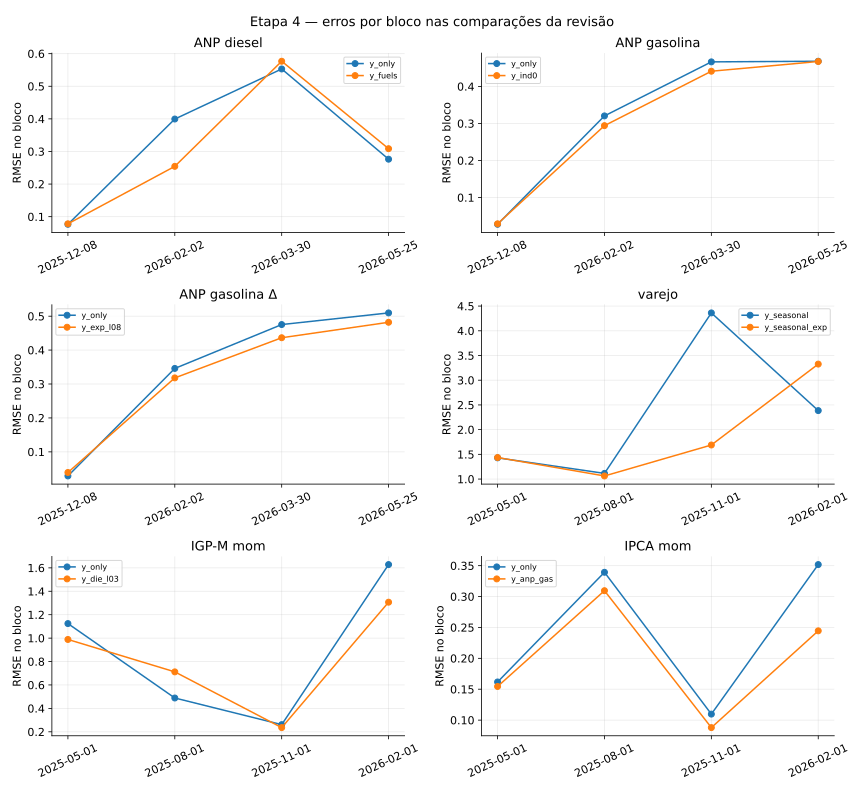

In [15]:
mx = json.loads((results / "etapa4_matrix.json").read_text(encoding="utf-8"))
print("sha", mx["sha256"][:16], "...")
print("naive", mx["data_revision"])
print("exclusões", mx["exclusions"])
q = mx["three_questions"]
print("onde PPI×vol", q["onde_contribui"])
print("onde gap", q["onde_gap_contribui"])
print("onde contexto", q["onde_contexto_contribui"])

rows = []
for r in mx["recommendations"]:
    rows.append({
        "vetor": r["vector"],
        "alvo": r["target"],
        "bloco de avaliação": r["horizon"],
        "controle": r["controle"],
        "RMSE ctrl": r["RMSE_controle"],
        "PPI×vol": r.get("melhor_ppi_x_vol"),
        "RMSE vol": r.get("RMSE_ppi_x_vol"),
        "vs y_only": r.get("ganho_vol_vs_y_only"),
        "critério exploratório PPI×vol": r["ppi_x_vol"],
        "formulacao": r["formulacao"],
        "resultado exploratório": r["sobrevive_validacao"],
    })
display(pd.DataFrame(rows))

display(target_table().round(5))
display(review_table().round(5))
display(Markdown(interpretation()))
display(SVG(filename=str(block_chart(project_root))))


### Leitura — matriz por alvo

O critério exige queda de RMSE mediano de pelo menos 5%, RMSE menor na maioria dos mesmos blocos e MAE mediano que não aumenta contra o controle correspondente. O desempate de 2% prefere a especificação mais simples. A matriz separa menor erro observado, evidência exploratória e critério atendido, porque o menor RMSE da grade não é o mesmo julgamento que as três condições. Não houve confirmação em amostra independente nem validação ex ante.

As comparações recalculadas aparecem abaixo nas tabelas da entrega; não se reproduzem as antigas afirmações de ganho em todos os blocos.
